# H1: styl życia a wiek i zainteresowania w predykcji prawego swipe'a

**Wersja po rebase na kontrakt danych v1 (2026-11-09)** (gałąź `fix/h1-rebase-v1`): dane z końcowymi decyzjami walidacji tagów (konsensus A + B + scalenia). Poprzednia wersja (po audycie 2026-11-08, mapowanie agenta = **v0**): `docs/h1/audit-fixes-2026-11-08.md`.
Zmiany, tabela *problem → ustalenie → zmiana → liczby v0 → v1* i oznaczenie „pre-rejestrowana / post hoc (walidacja tagów)”: `docs/h1/rebase-v1-2026-11-09.md`; kontrakt i hasze: `docs/data-contract-v1.md`; otwarte decyzje: `docs/h1/open-questions.md`.

## O co pytamy (po ludzku)

W aplikacji osoba **A** przegląda profil osoby **B** i przesuwa go w prawo (zainteresowana) albo w lewo (nie).
Hipoteza **H1** pyta: **czy zgodność stylu życia przewiduje prawy swipe silniej niż zgodność wieku i zainteresowań?**
Badamy **prawy swipe w aplikacji**, a nie faktyczny najem (D1); język jest ostrożny: „jest związane z”, „przewiduje”.

## Kryterium z karty M1 (sekcja 4, H1)

H1 jest potwierdzona, jeśli przyrost jakości dopasowania po dodaniu stylu życia jest **większy** niż po dodaniu wieku i zainteresowań,
a **przedział ufności różnicy nie obejmuje zera**. Wynik negatywny jest pełnoprawnym wynikiem. W tym notebooku to kryterium
sprawdzamy bezpośrednio: bootstrap klastrowany po nadawcach i po odbiorcach (szerszy z przedziałów = konserwatywny), obie kolejności
włączania bloków oraz walidacja krzyżowa po nadawcach ze sparowanymi różnicami.

## Jednostka, zmienna wynikowa, estymator

Jeden wiersz = jeden skierowany swipe A→B na profil; `y_right` = 1 dla prawego swipe'a. Regresja logistyczna; błędy standardowe
w modelu pełnym klastrowane dwustronnie (nadawca, odbiorca; **D18**). Log-wiarygodność nie zależy od estymatora wariancji, ale
**zakłada niezależne obserwacje**, więc same wartości ΔLL zawyżają siłę dowodu; dlatego o kryterium rozstrzygają przedziały z bootstrapu klastrowego.

## Specyfikacja po audycie

- **Kontrole identyczne we wszystkich modelach (Z1):** 8 dummies `sex_pair` (nadawca→odbiorca, referencja F→F; Z2) oraz `city_same`, `city_diff`.
- **Blok wieku (Z3):** `same_band`, `age_band_diff_abs` (odległość), `age_band_diff` (kierunek: odbiorca − nadawca). Wariant z `|diff|²` i z efektami stałymi pasma nadawcy w analizie wrażliwości.
- **Blok zainteresowań:** `interests_jaccard`, `interests_shared_n`, `interests_count_diff_abs`. Wariant z IDF-Jaccardem i z kontrolą sufitu 9 tagów (Z6).
- **Blok stylu życia:** `lifestyle_agree_ratio`, `lifestyle_tag_conflict`, `lifestyle_shared_tags_n` (+ analiza per pole, Z7).
- Wszystkie modele liczone na **tej samej próbie kompletnych przypadków** (n podany w lejku, Z8).

## Decyzje zespołu zastosowane tutaj

(`docs/prompts/m1-generation-plan.md`, `docs/codebook.md`): cechy z wersji profilu z dnia swipe'a (**D7**), bez Hyderabadu (**D10**),
płeć `O` osobno (**D8**), pasma 27+ połączone (**D9**), bez wykluczania kont skrajnych w analizie głównej (**D6**),
tagi stylu życia uzupełniają braki pól strukturalnych (**D12, D13**; klasyfikacja tagów i scalenia: końcowe decyzje walidacji tagów, jeden recenzent), obie kolejności włączania bloków (**D16**), foldy po użytkownikach (**D18**).

## Prywatność (G12)

Żadne pola `bio` nie są wczytywane. Do raportu trafiają wyłącznie agregaty; komórki z mniej niż 5 użytkownikami są tłumione.
Zbiór analityczny zawiera zbiory kanonicznych tagów hobby (kategorie, nie tekst użytkownika) i jest poza gitem.

In [1]:
import json
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

from rentfriends import h1, h1_audit, h1_rebase, h1_v1
from rentfriends.dataset_h1 import weighted_jaccard
from rentfriends.tagval_prep import sha256_file

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

SEED = 42  # stałe ziarno: bootstrap, permutacje, foldy CV
N_BOOT = 1000  # bootstrap klastrowy (>= 500 wg zadania)
N_BOOT_CV = 1000  # B >= 1000 także dla CV (w audycie 500)
N_PERM = 500
N_FOLDS = 5

PURPLE, PURPLE_INK, BLUE, GRAY, HAIR, CORAL = (
    "#A247E3",
    "#8B34C4",
    "#234CE0",
    "#595959",
    "#D5D2CB",
    "#D9534F",
)

DATA_DIR = Path("../data/processed")
DOCS_DIR = Path("../docs")
REBASE_DIR = Path("../reports/h1/rebase")

## 1. Wczytanie danych (kontrakt v1)

Zbiór `h1_analysis_dataset_v1.parquet` (cechy as-of wg **D7**, bez Hyderabadu **D10**, tagi oczyszczone wg **D12/D13**; klasyfikacja i mapowanie tagów: końcowe decyzje walidacji tagów, `docs/data-contract-v1.md`). Schemat i liczba wierszy jak w v0 (49 kolumn, 94 295 swipe'ów); zmieniają się tylko cechy pochodne od tagów. Sumy kontrolne v0 i v1 sprawdzane są względem `docs/data-contract-v1.md`.

In [2]:
for path in (DATA_DIR / h1_v1.V0_FILE, DATA_DIR / h1_v1.V1_FILE):
    digest = sha256_file(path)
    assert digest in (DOCS_DIR / "data-contract-v1.md").read_text(encoding="utf-8"), path.name
    print(f"{path.name}: SHA-256 {digest[:16]}… zgodny z docs/data-contract-v1.md")

df = h1_v1.load_v1(DATA_DIR)
print(f"Wczytano {df.shape[0]:,} obserwacji, {df.shape[1]} kolumn.")

# Kontrole prywatności i filtrów
assert not any("bio" in c.lower() for c in df.columns), "wykryto kolumny bio!"
users_raw = pd.read_parquet(DATA_DIR / "users.parquet", columns=["user_key", "city"])
hyd_users = set(users_raw.loc[users_raw["city"] == "Hyderabad", "user_key"])
assert not (df["user_key"].isin(hyd_users) | df["target_user_key"].isin(hyd_users)).any()
print("OK: brak kolumn bio, brak kont z Hyderabadu.")

# Cache wyników (poza gitem): ciężkie obliczenia liczą się raz, więc zmiana stylu
# wykresów nie wymaga ich powtarzania.
# Katalog zależy od sumy kontrolnej v1. Aby przeliczyć od zera, usuń katalog CACHE_DIR.
# (pickle importowany w pierwszej komórce)

CACHE_DIR = Path("../data/interim/h1_notebook") / sha256_file(DATA_DIR / h1_v1.V1_FILE)[:12]


def cached(name, compute):
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    path = CACHE_DIR / f"{name}.pkl"
    if path.exists():
        return pickle.loads(path.read_bytes())
    value = compute()
    path.write_bytes(pickle.dumps(value))
    return value

h1_analysis_dataset.parquet: SHA-256 7d15f84be3d173c8… zgodny z docs/data-contract-v1.md
h1_analysis_dataset_v1.parquet: SHA-256 fdbc9d3ec8b86b8e… zgodny z docs/data-contract-v1.md
Wczytano 94,295 obserwacji, 51 kolumn.
OK: brak kolumn bio, brak kont z Hyderabadu.


## Słownik zmiennych (zbiór danych H1)

Poniższe zestawienie wyjaśnia znaczenie operacyjne oraz sens istnienia w badaniu każdej z kolumn analitycznych przygotowanych w zbiorze `h1_analysis_dataset_v1.parquet` (v1; v0 = `h1_analysis_dataset.parquet`) 

### 1. Rekonstrukcja profilu as-of w czasie i analiza wrażliwości (D7, D6)
- **`source_flag_receiver`** (kategorie: `prior_version`, `first_version`, `users_current`): Źródło cech profilu odbiorcy. Wskazuje, czy profil pochodzi ściśle z wersji sprzed dnia decyzji (`prior_version` — brak wycieku danych z przyszłości), z pierwszej zarejestrowanej wersji (`first_version`), czy z tabeli bieżącej (`users_current`). Umożliwia weryfikację odporności (**D7**).
- **`source_flag_sender`** (kategorie: `prior_version`, `first_version`, `users_current`): Analogiczna flaga źródła profilu dla nadawcy swipe'a (**D7**).
- **`both_prior_version`** (0/1): Binarna flaga oznaczająca, że cechy profilu **obu** stron pochodzą ściśle ze stanu sprzed dnia decyzji. Służy jako filtr w najbardziej restrykcyjnym scenariuszu analizy wrażliwości (**D7**).
- **`sender_total_swipes`** (int): Łączna liczba swipe'ów wykonanych przez danego nadawcę. Pozwala kontrolować intensywność korzystania z aplikacji.
- **`sender_right_rate`** (float $[0, 1]$): Odsetek prawych swipe'ów nadawcy. Mierzy indywidualny poziom selektywności użytkownika (od osób bardzo wybrednych po klikające bez selekcji).
- **`is_low_activity`** (0/1): Flaga użytkownika o małej aktywności ($< 10$ swipe'ów). Służy w analizie wrażliwości (**D6**) do weryfikacji, czy incydentalni użytkownicy nie zniekształcają wyników.
- **`is_extreme_user`** (0/1): Flaga użytkownika o skrajnym zachowaniu ($0\%$ lub $100\%$ prawych swipe'ów — potencjalne boty lub użytkownicy nieselektywni). Używana do testu odporności w analizie wrażliwości (**D6**).

### 2. Kontrola demograficzna: Płeć (D8)
- **`sex_sender`** (kategorie: `F`, `M`, `O`): Płeć nadawcy swipe'a (zgodnie z **D8** płeć `O` stanowi odrębną kategorię). Podstawowa zmienna demograficzna.
- **`sex_receiver`** (kategorie: `F`, `M`, `O`): Płeć odbiorcy swipe'a.
- **`same_sex`** (0/1): Flaga tej samej płci nadawcy i odbiorcy. Kluczowa zmienna zakłócająca — preferencje dotyczące płci współlokatora (np. kobiety poszukujące wyłącznie współlokatorek) są jednym z najsilniejszych filtrów wstępnych na rynku najmu.
- **`sex_pair`** (kategorie: np. `F-F`, `M-M`, `F-M`, `M-F` itp.): Kategoryczny typ relacji płciowej w parze. Pozwala na pełną kontrolę interakcji płciowych w eksploracji i tabelach krzyżowych.

### 3. Blok Wieku (konkurencyjny wymiar demograficzny, D9)
- **`age_band_sender`** (kategorie: `18-20`, `21-23`, `24-26`, `27+`): Pasmo wieku nadawcy (po złączeniu pasm $27+$ wg **D9**).
- **`age_band_receiver`** (kategorie): Pasmo wieku odbiorcy (po złączeniu pasm $27+$ wg **D9**).
- **`same_band`** (0/1): Flaga tożsamości pasma wieku obu użytkowników. Podstawowa miara homofilii wiekowej — testuje, czy użytkownicy preferują osoby na dokładnie tym samym etapie życia.
- **`age_band_diff`** (int): Kierunkowa różnica rang pasm wieku ($\text{odbiorca} - \text{nadawca}$). To jest **kierunek, nie podobieństwo wieku**: wartość 0 oznacza to samo pasmo, a znak mówi tylko, czy odbiorca jest starszy czy młodszy. Nadawca z pasma 18-20 nie może mieć wartości ujemnych (65% profili to 18-20).
- **`age_band_diff_abs`** (int): Bezwzględna różnica rang pasm wieku ($|\text{diff}|$). Mierzy odległość pokoleniową między użytkownikami niezależnie od kierunku.

### 4. Kontrola geograficzna: Miasto (D10)
- **`city_sender`** (str): Miasto zadeklarowane przez nadawcę (po wykluczeniu kont z Hyderabadu wg **D10**).
- **`city_receiver`** (str): Miasto zadeklarowane przez odbiorcę (po wykluczeniu kont z Hyderabadu wg **D10**).
- **`same_city`** (kategorie: `same`, `different`, `unknown`): Kategoryczna zgodność lokalizacji nadawcy i odbiorcy.
- **`city_same`** (0/1): Binarna zmienna dummy oznaczająca, że nadawca i odbiorca deklarują to samo znane miasto. Używana w regresji logistycznej do wychwycenia premii za wspólne miasto.
- **`city_diff`** (0/1): Binarna zmienna dummy oznaczająca, że nadawca i odbiorca deklarują różne znane miasta. Używana w regresji logistycznej do kontroli kosztu poszukiwania lokalu w innym mieście.

### 5. Blok Stylu Życia (główny badany wymiar hipotezy H1, D12, D13)
- **`lifestyle_agreed_count`** (int): Liczba cech stylu życia, w których obie strony mają identyczną deklarację (po uzupełnieniu braków tagami wg **D13**). Licznik zgodności nawyków (czystość, hałas, palenie, alkohol, rytm dnia, praca zdalna).
- **`lifestyle_known_count`** (int): Liczba cech stylu życia zadeklarowanych przez obie osoby. Stanowi mianownik wskaźnika zgodności i zabezpiecza przed zniekształceniem estymacji przez brak danych.
- **`lifestyle_agree_ratio`** (float $[0, 1]$): Syntetyczny wskaźnik zgodności codziennych nawyków ($\frac{\text{lifestyle\_agreed\_count}}{\text{lifestyle\_known\_count}}$). Główny skalar mierzący kompatybilność współlokatorską w hipotezie H1.
- **`lifestyle_shared_tags_n`** (int): Liczba wspólnych tagów tożsamościowych związanych ze stylem życia. Mierzy afirmatywne podobieństwo deklaracji.
- **`lifestyle_tag_conflict`** (0/1): Binarna flaga bezpośredniego konfliktu kierunkowego na kluczowych nawykach (np. palący vs niepalący, głośny vs cichy, ranny ptaszek vs nocny marek). W odróżnieniu od ogólnej zgodności wychwytuje tzw. *deal-breakery*, które mogą natychmiastowo dyskwalifikować drugą osobę.

### 6. Blok Zainteresowań i Hobby (konkurencyjny wymiar behawioralny, D12, D13)
- **`interests_jaccard`** (float $[0, 1]$): Indeks podobieństwa Jaccarda ($\frac{|A \cap B|}{|A \cup B|}$) liczony wyłącznie na czystych zainteresowaniach (po usunięciu tagów stylu życia wg **D12/D13**). Główny znormalizowany wskaźnik zbieżności pasji i tematów do rozmowy w konkurencyjnym bloku H1.
- **`interests_shared_n`** (int): Bezwzględna liczba wspólnych zainteresowań ($|A \cap B|$). Mierzy wolumen wspólnych pasji (pozwala odróżnić parę o 3 wspólnych hobby od pary o 1 wspólnym hobby przy identycznym indeksie Jaccarda).
- **`interests_count_sender`** (int): Liczba zainteresowań zadeklarowanych przez nadawcę. Wskaźnik zaangażowania profilowego i ekspresji nadawcy.
- **`interests_count_receiver`** (int): Liczba zainteresowań zadeklarowanych przez odbiorcę. Wskaźnik bogactwa profilu odbiorcy (widoczny na pierwszej karcie).
- **`interests_count_diff`** (int): Kierunkowa różnica liczby zainteresowań ($\text{odbiorca} - \text{nadawca}$). Mierzy asymetrię ekspresji hobby.
- **`interests_count_diff_abs`** (int): Bezwzględna różnica liczby zainteresowań. Kontroluje dysproporcję w nakładzie pracy i stopniu wypełnienia profilu między stronami.


### 7. Kolumny dodane w audycie 2026-11-08 (Z6, Z7)
- **`interests_idf_jaccard`** (float $[0, 1]$): Jaccard ważony IDF, waga tagu $\log(N/\text{df})$, $N$ = użytkownicy bez Hyderabadu, df liczone na bieżących, oczyszczonych tagach hobby. Wspólny rzadki tag liczy się bardziej niż popularny.
- **`raw_tags_n_sender`, `raw_tags_n_receiver`** (int): surowa liczba tagów profilu przed deduplikacją i podziałem na kategorie (maks. 9 w aplikacji).
- **`interests_at_cap`** (0/1): 1, gdy profil którejkolwiek strony ma 9 surowych tagów (sufit). Kontrola Z6c.
- **`interests_set_sender`, `interests_set_receiver`** (lista): kanoniczne tagi hobby po stronie swipe'a (kategorie, nie tekst użytkownika); służą baseline'owi permutacyjnemu.
- **`lsf_<pole>`** (`agree` / `disagree` / `one_missing` / `both_missing`): status pary w każdym z 7 pól strukturalnych stylu życia (po uzupełnieniu tagami, D13).
- **`smoking_direction`**: kierunkowy status palenia. Założenie bez codebooka (D14): kod `N` = niepalący, pozostałe kody (`V`, `O`, `Y`) = użytkownik.

## 2. Lejek próby (Z8)

Jeden lejek od wszystkich swipe'ów do próby modelu głównego. Trzy liczby, które wcześniej się różniły, mają tu jedno wyjaśnienie:
- **93 717** to próba H2/H3a: znane pasma wieku obu stron;
- **92 754** to próba H1: dodatkowo co najmniej jedno pole stylu życia znane u obu stron (wskaźnik zgodności nie istnieje bez niego);
- **93 330** w poprzednim lejku tego notebooka powstało przez błąd: krok „kompletne obserwacje” sprawdzał `same_band`, które **nigdy nie jest NaN** (brak pasma daje 0, a nie NaN),
  więc odfiltrował tylko wiersze bez wskaźnika zgodności. Model i tak odrzucał wiersze bez pasma przez `age_band_diff`, stąd 92 754.

In [3]:
swipes_raw = pd.read_parquet(
    DATA_DIR / "swipes.parquet", columns=["target_type", "target_user_key"]
)
n_all = len(swipes_raw)
n_profile = int(
    ((swipes_raw["target_type"] == "profile") & swipes_raw["target_user_key"].notna()).sum()
)
del swipes_raw

funnel = h1_audit.sample_funnel(df, n_all_swipes=n_all, n_profile_swipes=n_profile)
display(funnel)

print("Rozkład źródeł wersji profilu as-of (D7) dla odbiorcy:")
print(df["source_flag_receiver"].value_counts(normalize=True).apply(lambda p: f"{p:.1%}"))
print(
    "\nUdział swipe'ów, w których profil którejkolwiek strony ma 9 surowych tagów (sufit):",
    f"{df['interests_at_cap'].mean():.1%}",
)
print(
    "Maks. liczba tagów hobby po oczyszczeniu: nadawca",
    int(df["interests_count_sender"].max()),
    "| odbiorca",
    int(df["interests_count_receiver"].max()),
    "(sufit 9 po oczyszczeniu prawie nie występuje)",
)

,step,swipes,dropped,right,senders,receivers
0,wszystkie swipe'y,116414,NaN,NaN,NaN,NaN
1,swipe'y na profile,95144,21270.0000,NaN,NaN,NaN
2,po wykluczeniu Hyderabadu (D10),94295,849.0000,19363.0000,1544.0000,1363.0000
3,+ znane pasma wieku obu stron (= H2/H3a),93717,578.0000,19325.0000,1538.0000,1359.0000
4,"+ >= 1 pole stylu zycia znane u obu (= H1, mod...",92754,963.0000,19208.0000,1525.0000,1354.0000


Rozkład źródeł wersji profilu as-of (D7) dla odbiorcy:
source_flag_receiver
prior_version    93.4%
first_version     5.8%
users_current     0.7%
Name: proportion, dtype: str

Udział swipe'ów, w których profil którejkolwiek strony ma 9 surowych tagów (sufit): 82.9%
Maks. liczba tagów hobby po oczyszczeniu: nadawca 8 | odbiorca 8 (sufit 9 po oczyszczeniu prawie nie występuje)


## 3. Eksploracja: wskaźniki akceptacji wg stylu życia, wieku i zainteresowań

Odsetek prawych swipe'ów w grupach, z przedziałami z **bootstrapu klastrowanego po nadawcach** (opis, bez kontroli innych zmiennych).
Tercyle zgodności stylu życia liczone są **tylko na wierszach ze znanym polem**; wiersze bez żadnego wspólnie znanego pola to osobna kategoria
„brak danych” (poprzednio `fillna(0)` mieszało je z niską zgodnością). Uwaga: `cleanliness` i `noise_level` mają ok. 1% braków i mogą być
wartościami domyślnymi (P6), więc ich „zgodność” bywa sztucznie zawyżona.

In [4]:
tbl_conflict = cached(
    "tbl_conflict",
    lambda: h1.cluster_bootstrap_rate_table(df, "lifestyle_tag_conflict", n_boot=N_BOOT, seed=SEED),
)
tbl_conflict["kategoria"] = tbl_conflict["kategoria"].map(
    {0: "Brak konfliktu (0)", 1: "Konflikt (1)"}
)

df["agree_tercyle"] = h1.lifestyle_agree_groups(df)
tbl_agree = cached(
    "tbl_agree",
    lambda: h1.cluster_bootstrap_rate_table(df, "agree_tercyle", n_boot=N_BOOT, seed=SEED),
)
order = list(df["agree_tercyle"].cat.categories)
tbl_agree = tbl_agree.set_index("kategoria").loc[order].reset_index()

df["jaccard_group"] = pd.qcut(
    df["interests_jaccard"],
    q=[0, 0.75, 1.0],
    labels=["Niski / brak Jaccarda", "Wysoki Jaccard (> 0.125)"],
)
tbl_jaccard = cached(
    "tbl_jaccard",
    lambda: h1.cluster_bootstrap_rate_table(df, "jaccard_group", n_boot=N_BOOT, seed=SEED),
)

tbl_age = cached(
    "tbl_age", lambda: h1.cluster_bootstrap_rate_table(df, "same_band", n_boot=N_BOOT, seed=SEED)
)
tbl_age["kategoria"] = tbl_age["kategoria"].map({0.0: "Różne pasmo (0)", 1.0: "To samo pasmo (1)"})

cols = ["kategoria", "n_swipe", "odsetek_prawych", "ci_low_boot", "ci_high_boot"]
for title, t in [
    ("konfliktu stylu życia", tbl_conflict),
    ("zgodności pól stylu życia (tercyle + brak danych)", tbl_agree),
    ("podobieństwa zainteresowań", tbl_jaccard),
    ("zgodności pasma wieku", tbl_age),
]:
    print(f"--- Odsetek prawych swipe'ów wg {title} ---")
    display(t[cols])

--- Odsetek prawych swipe'ów wg konfliktu stylu życia ---


,kategoria,n_swipe,odsetek_prawych,ci_low_boot,ci_high_boot
0,Brak konfliktu (0),45439,0.2072,0.1821,0.2311
1,Konflikt (1),48856,0.2037,0.1786,0.2292


--- Odsetek prawych swipe'ów wg zgodności pól stylu życia (tercyle + brak danych) ---


,kategoria,n_swipe,odsetek_prawych,ci_low_boot,ci_high_boot
0,Niski (-0.00-0.33],39707,0.2016,0.1754,0.2284
1,Średni (0.33-0.50],22998,0.1993,0.1745,0.2232
2,Wysoki (0.50-1.00],30625,0.2174,0.1912,0.2446
3,brak danych,965,0.1212,0.0561,0.2076


--- Odsetek prawych swipe'ów wg podobieństwa zainteresowań ---


,kategoria,n_swipe,odsetek_prawych,ci_low_boot,ci_high_boot
0,Niski / brak Jaccarda,72036,0.2018,0.1765,0.2266
1,Wysoki Jaccard (> 0.125),22259,0.2168,0.1915,0.2424


--- Odsetek prawych swipe'ów wg zgodności pasma wieku ---


,kategoria,n_swipe,odsetek_prawych,ci_low_boot,ci_high_boot
0,Różne pasmo (0),49086,0.1983,0.1666,0.2276
1,To samo pasmo (1),45209,0.2129,0.1877,0.2372


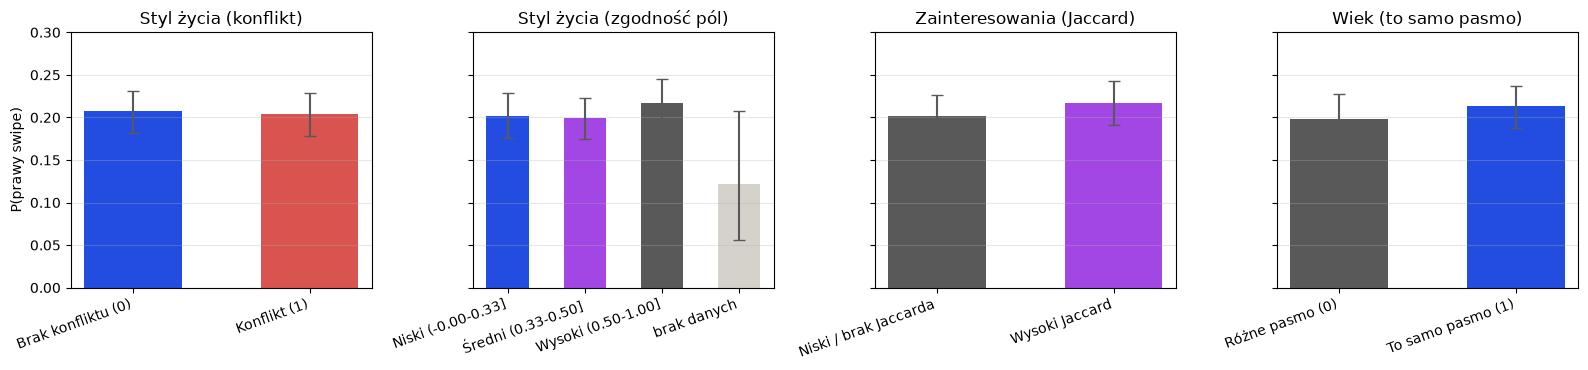

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
panels = [
    (axes[0], tbl_conflict, "Styl życia (konflikt)", [BLUE, CORAL]),
    (axes[1], tbl_agree, "Styl życia (zgodność pól)", [BLUE, PURPLE, GRAY, HAIR][: len(tbl_agree)]),
    (axes[2], tbl_jaccard, "Zainteresowania (Jaccard)", [GRAY, PURPLE]),
    (axes[3], tbl_age, "Wiek (to samo pasmo)", [GRAY, BLUE]),
]
for ax, t, title, colors in panels:
    y = t["odsetek_prawych"].to_numpy()
    ax.bar(range(len(t)), y, color=colors, width=0.55)
    ax.errorbar(
        range(len(t)),
        y,
        yerr=[y - t["ci_low_boot"], t["ci_high_boot"] - y],
        fmt="none",
        color=GRAY,
        capsize=4,
        lw=1.5,
    )
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(
        [k.split(" (")[0] if len(k) > 22 else k for k in t["kategoria"]], rotation=20, ha="right"
    )
    ax.set_title(title)
    ax.set_ylim(0, 0.3)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("P(prawy swipe)")
plt.tight_layout()
plt.show()

## 4. Wiek: kierunek, nie podobieństwo (Z3)

`age_band_diff` (odbiorca − nadawca) mówi o **kierunku**; poprzedni wniosek („preferencja podobnego wieku”) mylił go z podobieństwem. Sprawdzamy wprost, czy odbiorca
młodszy o jedno pasmo ma wyższe szanse niż ta sama grupa wiekowa: stawki wewnątrz pasma nadawcy, kontrast z bootstrapu po nadawcach
oraz logit z efektami stałymi pasma nadawcy (SE klastrowane po nadawcy). Pasmo 18-20 nie może mieć młodszych odbiorców, więc nie ma kontrastu.
Komórki z mniej niż 5 nadawcami są tłumione.

In [6]:
age_res = cached("age_res", lambda: h1_audit.age_direction_check(df, n_boot=N_BOOT, seed=SEED))
print(
    "Odsetek prawych swipe'ów: pasmo nadawcy × różnica pasm (odbiorca − nadawca);"
    " NaN = komórka stłumiona (< 5 nadawców)"
)
display(age_res["cells"].pivot(index="age_band_sender", columns="age_band_diff", values="rate"))
print(
    "Kontrast: P(prawy | odbiorca młodszy o 1 pasmo) − P(prawy | to samo pasmo),"
    " wewnątrz pasma nadawcy (95% CI, bootstrap po nadawcach)"
)
display(age_res["contrast"])
print("Logit z FE pasma nadawcy: OR względem tego samego pasma (95% CI, SE klastrowane po nadawcy)")
display(age_res["pooled"])

Odsetek prawych swipe'ów: pasmo nadawcy × różnica pasm (odbiorca − nadawca); NaN = komórka stłumiona (< 5 nadawców)


age_band_diff,-3,-2,-1,0,1,2,3
age_band_sender,,,,,,,
18-20,NaN,NaN,NaN,0.2051,0.1374,0.0948,0.0657
21-23,NaN,NaN,0.2627,0.2713,0.2049,0.1195,NaN
24-26,NaN,0.3013,0.3131,0.2700,0.1746,NaN,NaN
27+,0.2419,0.2152,0.2362,0.2534,NaN,NaN,NaN


Kontrast: P(prawy | odbiorca młodszy o 1 pasmo) − P(prawy | to samo pasmo), wewnątrz pasma nadawcy (95% CI, bootstrap po nadawcach)


,age_band_sender,n_same,n_younger,n_users,rate_same,rate_younger,diff_younger_minus_same,ci_low,ci_high
0,21-23,3981,12819,310,0.2713,0.2627,-0.0086,-0.0318,0.0136
1,24-26,811,1763,135,0.2700,0.3131,0.0431,0.0042,0.0849
2,27+,801,741,137,0.2534,0.2362,-0.0173,-0.0643,0.0334


Logit z FE pasma nadawcy: OR względem tego samego pasma (95% CI, SE klastrowane po nadawcy)


,term,coef,se,or,ci_low,ci_high,p_value
0,younger_by_2plus,-0.0038,0.1008,0.9963,0.8176,1.2139,0.9703
1,younger_by_1,-0.0275,0.0583,0.9728,0.8677,1.0907,0.6369
2,older_by_1,-0.4765,0.0476,0.6210,0.5656,0.6817,0.0000
3,older_by_2plus,-1.0378,0.0983,0.3542,0.2921,0.4295,0.0000


## 5. Zainteresowania: IDF-Jaccard i baseline losowych par (Z6)

Czy wspólne hobby u prawych swipe'ów to więcej niż przypadek? Baseline: zbiory hobby odbiorców tasowane między swipe'ami **w obrębie równej liczby tagów**
(zachowana liczba tagów i rozkład tagów, zerwana zgodność nadawca–odbiorca). Porównujemy średni Jaccard prawych i lewych swipe'ów z rozkładem z permutacji.
Dla wartości obserwowanych podajemy CI z bootstrapu po nadawcach. **Uwaga:** p z permutacji traktuje swipe'y jako wymienne i nie uwzględnia klastrowania po użytkownikach,
więc jest zbyt optymistyczne; rozstrzyga CI klastrowane. Wariant IDF używa tych samych wag co kolumna `interests_idf_jaccard`.

In [7]:
v1_kwargs, _ = h1_v1.v1_inputs(DOCS_DIR, DOCS_DIR / "tag-validation")
idf_w, idf_unseen = h1_v1.user_idf(DATA_DIR, DOCS_DIR, **v1_kwargs)  # wagi IDF słownika v1
# spójność: kolumna datasetu = jaccard ważony wagami z users (próbka)
chk = df.sample(2000, random_state=SEED)
recomputed = [
    weighted_jaccard(s, r, idf_w, idf_unseen)
    for s, r in zip(chk["interests_set_sender"], chk["interests_set_receiver"], strict=True)
]
assert np.allclose(recomputed, chk["interests_idf_jaccard"], atol=1e-6)

perm_plain = cached(
    "perm_plain", lambda: h1_audit.interests_permutation_baseline(df, n_perm=N_PERM, seed=SEED)
)
perm_idf = cached(
    "perm_idf",
    lambda: h1_audit.interests_permutation_baseline(
        df, n_perm=N_PERM, seed=SEED, weights=idf_w, default_weight=idf_unseen
    ),
)
for name, res in [("zwykły Jaccard", perm_plain), ("IDF-Jaccard", perm_idf)]:
    print(
        f"--- {name}: prawe vs lewe swipe'y, obserwowane vs permutacje"
        f" (n = {res['n_swipes']:,}) ---"
    )
    display(res["summary"].round(4))
print(
    "p_two_sided = 1/(N_PERM+1) = minimum rozdzielczości testu"
    " przy 500 permutacjach; nie jest to p = 0."
)

--- zwykły Jaccard: prawe vs lewe swipe'y, obserwowane vs permutacje (n = 94,295) ---


,group,observed,obs_ci_low,obs_ci_high,perm_mean,perm_lo,perm_hi,p_two_sided
0,right,0.0667,0.0605,0.0722,0.0622,0.0607,0.0638,NaN
1,left,0.0618,0.0585,0.0649,0.0619,0.0612,0.0628,NaN
2,right_minus_left,0.0049,-0.0011,0.0108,0.0003,-0.0016,0.0020,0.0020


--- IDF-Jaccard: prawe vs lewe swipe'y, obserwowane vs permutacje (n = 94,295) ---


,group,observed,obs_ci_low,obs_ci_high,perm_mean,perm_lo,perm_hi,p_two_sided
0,right,0.0579,0.0526,0.0625,0.0538,0.0523,0.0552,NaN
1,left,0.0537,0.0508,0.0563,0.0538,0.0531,0.0546,NaN
2,right_minus_left,0.0042,-0.0009,0.0094,-0.0000,-0.0017,0.0016,0.0020


p_two_sided = 1/(N_PERM+1) = minimum rozdzielczości testu przy 500 permutacjach; nie jest to p = 0.


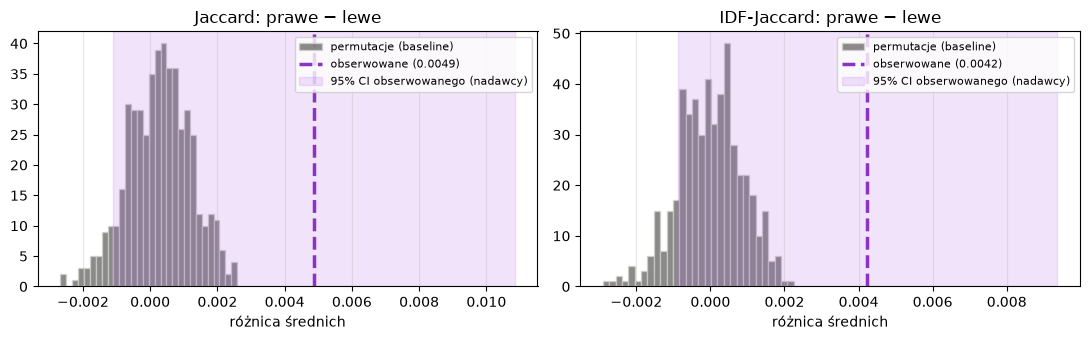

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, res) in zip(axes, [("Jaccard", perm_plain), ("IDF-Jaccard", perm_idf)], strict=True):
    ax.hist(
        res["perm_diff"],
        bins=30,
        color=GRAY,
        alpha=0.7,
        edgecolor=HAIR,
        label="permutacje (baseline)",
    )
    obs = res["summary"].set_index("group").loc["right_minus_left"]
    ax.axvline(
        obs["observed"],
        color=PURPLE_INK,
        lw=2.5,
        ls="--",
        label=f"obserwowane ({obs['observed']:.4f})",
    )
    ax.axvspan(
        obs["obs_ci_low"],
        obs["obs_ci_high"],
        color=PURPLE,
        alpha=0.15,
        label="95% CI obserwowanego (nadawcy)",
    )
    ax.set_title(f"{name}: prawe − lewe")
    ax.set_xlabel("różnica średnich")
    ax.legend(frameon=True, fontsize=8)
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Główny wynik: trzy bloki, identyczne kontrole (Z1, Z2, Z4)

### 6.1 Odtworzenie liczb sprzed zmian (v0)

Zanim policzymy cokolwiek na v1, odtwarzamy **v0** (mapowanie agenta) i sprawdzamy zgodność z `docs/h1/audit-fixes-2026-11-08.md`: n = 92 754, średni ΔLL po 6 kolejnościach: wiek 533,19; zainteresowania 13,93; styl życia 42,51 (publikowane z dokładnością do 2 miejsc, więc porównujemy po zaokrągleniu). Dodatkowo `spec_old` na v0 musi dać liczby sprzed audytu: ΔLL stylu życia 41,38, ΔLL wieku+zainteresowań 739,14, CV AUC (null 0,500; styl życia 0,519; wiek+zainteresowania 0,581; pełny 0,584).

In [9]:
df_v0 = h1.load_h1_data(DATA_DIR)  # kontrakt v0, tylko do odtworzenia; nie jest nadpisywany
res_v0 = h1.fit_h1_logit_models(df_v0)
inc_v0 = h1_audit.block_increments_from_fit(res_v0).set_index("block")
published_v0 = {"age": 533.19, "interests": 13.93, "lifestyle": 42.51}
repro_v0 = pd.DataFrame(
    {
        "audyt 2026-11-08": [92754, *published_v0.values()],
        "odtworzone (v0)": [res_v0["data_len"], *[inc_v0.loc[b, "dll_mean"] for b in published_v0]],
    },
    index=[
        "n głównej próby",
        "ΔLL wiek (średnia)",
        "ΔLL zainteresowania (średnia)",
        "ΔLL styl życia (średnia)",
    ],
)
display(repro_v0.round(3))
assert res_v0["data_len"] == 92754
assert all(round(inc_v0.loc[b, "dll_mean"], 2) == v for b, v in published_v0.items())
print("OK: v0 odtworzony zgodnie z audytem (po zaokrągleniu do 2 miejsc).")

legacy = h1.fit_h1_logit_models(df_v0, h1.LEGACY_SPEC)
cv_legacy = cached(
    "cv_legacy", lambda: h1.grouped_cv_h1(df_v0, n_splits=N_FOLDS, seed=SEED, spec=h1.LEGACY_SPEC)
)
auc_legacy = cv_legacy.groupby("block")["auc"].mean()
repro = pd.DataFrame(
    {
        "wartość sprzed audytu": [92754, 41.38, 739.14, 0.500, 0.519, 0.581, 0.584],
        "odtworzona (spec_old, v0)": [
            legacy["data_len"],
            round(legacy["delta_lifestyle_over_interests_ll"], 2),
            round(legacy["delta_interests_over_lifestyle_ll"], 2),
            round(auc_legacy["null"], 3),
            round(auc_legacy["lifestyle"], 3),
            round(auc_legacy["age_interests"], 3),
            round(auc_legacy["full"], 3),
        ],
    },
    index=[
        "n głównej próby",
        "ΔLL styl życia",
        "ΔLL wiek+zainteresowania",
        "CV AUC null",
        "CV AUC styl życia",
        "CV AUC wiek+zainteresowania",
        "CV AUC pełny",
    ],
)
display(repro)
assert (
    repro["wartość sprzed audytu"].astype(float) - repro["odtworzona (spec_old, v0)"].astype(float)
).abs().max() < 1e-3 + 5e-3
print("OK: liczby sprzed audytu odtworzone na v0.")

,audyt 2026-11-08,odtworzone (v0)
n głównej próby,92754.0000,92754.0000
ΔLL wiek (średnia),533.1900,533.1890
ΔLL zainteresowania (średnia),13.9300,13.9260
ΔLL styl życia (średnia),42.5100,42.5090


OK: v0 odtworzony zgodnie z audytem (po zaokrągleniu do 2 miejsc).


,wartość sprzed audytu,"odtworzona (spec_old, v0)"
n głównej próby,92754.0000,92754.0000
ΔLL styl życia,41.3800,41.3800
ΔLL wiek+zainteresowania,739.1400,739.1400
CV AUC null,0.5000,0.5000
CV AUC styl życia,0.5190,0.5190
CV AUC wiek+zainteresowania,0.5810,0.5810
CV AUC pełny,0.5840,0.5840


OK: liczby sprzed audytu odtworzone na v0.


### 6.2 Model po audycie: te same kontrole we wszystkich modelach

Modele: `controls` (same kontrole), trzy bloki osobno, trzy pary, pełny. Tabela `summary` pokazuje liczbę zmiennych: każdy model zawiera te same kontrole
(Z1; poprzednio `lifestyle` nie miał kontroli płci ani wieku). Współczynniki `sex_<para>` z mniej niż 5 użytkownikami są tłumione.

In [10]:
h1_res = h1.fit_h1_logit_models(df)
print(f"n = {h1_res['data_len']:,}; kontrole w każdym modelu: {h1_res['control_names']}")
display(h1_res["summary"])
counts = h1_audit.sex_pair_user_counts(df)
or_tbl = h1_audit.mask_small_cells(
    h1_res["odds_ratios"][["zmienna", "coef", "se", "or", "ci_low", "ci_high", "p_value"]], counts
)
print("Ilorazy szans w modelu pełnym (SE klastrowane dwustronnie)")
display(or_tbl.round(3))

n = 92,754; kontrole w każdym modelu: ['sex_F_M', 'sex_F_O', 'sex_M_F', 'sex_M_M', 'sex_M_O', 'sex_O_F', 'sex_O_M', 'sex_O_O', 'city_same', 'city_diff']


,model,n_vars,llf,aic,bic,pseudo_r2
0,null,0,-47310.9738,94623.9477,94633.3854,0.0000
1,controls,10,-45511.8815,91045.7631,91149.5778,0.0380
2,age,13,-44973.6609,89975.3217,90107.4496,0.0494
3,interests,13,-45488.5196,91005.0392,91137.1671,0.0385
4,lifestyle,13,-45476.8687,90981.7375,91113.8654,0.0388
5,age_interests,16,-44952.7688,89939.5376,90099.9786,0.0498
6,age_lifestyle,16,-44945.4286,89924.8573,90085.2983,0.0500
7,interests_lifestyle,16,-45451.9336,90937.8672,91098.3082,0.0393
8,full,19,-44922.4350,89884.8700,90073.6241,0.0505


Ilorazy szans w modelu pełnym (SE klastrowane dwustronnie)


,zmienna,coef,se,or,ci_low,ci_high,p_value,suppressed
0,const,-0.9990,0.2340,0.3680,0.2330,0.5830,0.0000,False
1,sex_F_M,-0.8800,0.1280,0.4150,0.3230,0.5340,0.0000,False
2,sex_F_O,-0.7150,0.2070,0.4890,0.3260,0.7330,0.0010,False
3,sex_M_F,0.5030,0.1450,1.6540,1.2450,2.1980,0.0010,False
4,sex_M_M,0.0720,0.1520,1.0740,0.7980,1.4460,0.6370,False
5,sex_M_O,-0.0900,0.2150,0.9140,0.5990,1.3940,0.6770,False
6,sex_O_F,0.8130,0.3750,2.2540,1.0820,4.6980,0.0300,False
7,sex_O_M,1.2680,0.4240,3.5550,1.5480,8.1640,0.0030,False
8,sex_O_O,1.1170,0.5650,3.0560,1.0090,9.2560,0.0480,False
9,city_same,-0.2320,0.1790,0.7930,0.5580,1.1260,0.1950,False


### 6.3 Przyrost każdego z trzech bloków (Z4)

Dla każdego bloku: ΔLL **jako pierwszy** (ponad kontrole), **jako ostatni** (ponad dwa pozostałe) i **średnia po wszystkich 6 kolejnościach** (wartość Shapleya; trzy średnie sumują się do ΔLL pełnego modelu).
Bloki mają po 3 zmienne, ale raportujemy też ΔLL na stopień swobody i ΔAIC (ujemny = blok się opłaca). Wiersz `age+interests` to porównanie z karty (styl życia vs wiek+zainteresowania).

,df,dll_first,dll_first_per_df,daic_first,dll_last,dll_last_per_df,daic_last,dll_mean,dll_mean_per_df,daic_mean
block,,,,,,,,,,
age,3,538.2200,179.4100,-1070.4400,529.5000,176.5000,-1053.0000,533.7700,177.9200,-1061.5400
interests,3,23.3600,7.7900,-40.7200,22.9900,7.6600,-39.9900,23.0900,7.7000,-40.1800
lifestyle,3,35.0100,11.6700,-64.0300,30.3300,10.1100,-54.6700,32.5900,10.8600,-59.1700
age+interests,6,559.1100,93.1900,-1106.2300,554.4300,92.4100,-1096.8700,556.7700,92.8000,-1101.5500


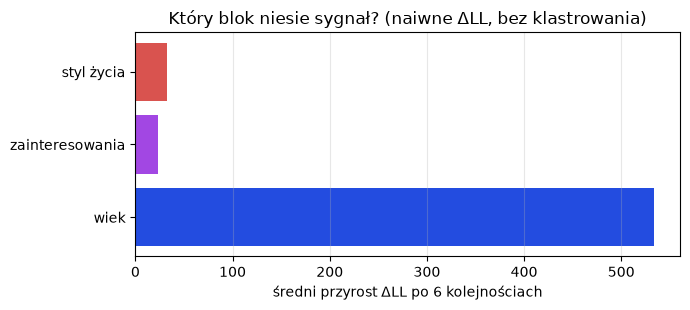

In [11]:
inc = h1_audit.block_increments_from_fit(h1_res)
display(inc.set_index("block").round(2))

fig, ax = plt.subplots(figsize=(7, 3.2))
b3 = inc.set_index("block").loc[["age", "interests", "lifestyle"]]
ax.barh(["wiek", "zainteresowania", "styl życia"], b3["dll_mean"], color=[BLUE, PURPLE, CORAL])
ax.set_xlabel("średni przyrost ΔLL po 6 kolejnościach")
ax.set_title("Który blok niesie sygnał? (naiwne ΔLL, bez klastrowania)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.4 Kryterium z karty: CI różnicy przyrostów (Z5)

Różnica ΔLL(styl życia) − ΔLL(wiek+zainteresowania) oraz − ΔLL(zainteresowania), − ΔLL(wiek). Bootstrap klastrowy (`N_BOOT` = 1000, stałe ziarno):
raz z losowaniem **nadawców**, raz **odbiorców**; kolumny `*_conservative` to szerszy z dwóch przedziałów.
Definicje „pierwszy/ostatni” dają tę samą różnicę dla `age+interests` (algebraicznie: (L−C) − (AI−C) = (F−AI) − (F−L) = L − AI); średnia po kolejnościach jest jej bliska.
Dodatnia różnica = styl życia ma większy przyrost. H1 jest potwierdzona tylko wtedy, gdy różnica jest dodatnia i CI nie obejmuje zera.

In [12]:
block_df = {"age": 3, "interests": 3, "lifestyle": 3}
tabs, boots = {}, {}
for col in ("user_key", "target_user_key"):
    obs_ll, boot_ll = cached(
        f"boot_{col}",
        lambda col=col: h1_audit.bootstrap_model_loglik(
            df, cluster_col=col, n_boot=N_BOOT, seed=SEED
        ),
    )
    boots[col] = (obs_ll, boot_ll)
    tabs[col] = h1_audit.summarise_block_differences(obs_ll, boot_ll, block_df)
diff_ci = h1_audit.combine_cluster_cis(tabs["user_key"], tabs["target_user_key"])
display(diff_ci.round(2))

,definition,contrast,estimate,ci_low_sender,ci_high_sender,ci_low_receiver,ci_high_receiver,ci_low_conservative,ci_high_conservative,wider_is,excludes_zero_conservative
0,first,lifestyle - age+interests,-524.1000,-905.6200,-323.4000,-620.8100,-439.3000,-905.6200,-323.4000,sender,True
1,first,lifestyle - interests,11.6500,-77.4200,95.4200,-14.4900,38.2800,-77.4200,95.4200,sender,False
2,first,lifestyle - age,-503.2100,-858.2800,-283.0300,-597.6600,-413.7700,-858.2800,-283.0300,sender,True
3,last,lifestyle - age+interests,-524.1000,-905.6200,-323.4000,-620.8100,-439.3000,-905.6200,-323.4000,sender,True
4,last,lifestyle - interests,7.3400,-81.4000,83.0000,-16.3200,31.9900,-81.4000,83.0000,sender,False
5,last,lifestyle - age,-499.1600,-855.8600,-276.7800,-593.7800,-410.9300,-855.8600,-276.7800,sender,True
6,mean,lifestyle - age+interests,-524.1900,-905.7300,-323.6100,-620.9300,-439.2400,-905.7300,-323.6100,sender,True
7,mean,lifestyle - interests,9.5000,-78.1700,88.9300,-15.9000,34.9700,-78.1700,88.9300,sender,False
8,mean,lifestyle - age,-501.1900,-857.1000,-277.9900,-594.5900,-412.4100,-857.1000,-277.9900,sender,True


### 6.4b Przyrosty bloków z CI i stosunek styl życia / zainteresowania (Z3, Z4; post hoc: walidacja tagów)

Te same losowania bootstrapu (ziarno 42, B = 1000, osobno po nadawcach i po odbiorcach; konserwatywny = szerszy przedział) dają CI dla **ΔLL każdego bloku**
(jako pierwszy / ostatni / średnia po 6 kolejnościach), dla różnic oraz dla **stosunku ΔLL stylu życia do zainteresowań** i udziału bloków w sumie ΔLL.
Przedziały są percentylami rozkładu bootstrapowego (bez korekty obciążenia), więc przyrosty mają przedziały asymetryczne i szerokie (`open-questions.md`, Q15); kryterium H1 opiera się na przedziałach **różnic** przyrostów.

In [13]:
quant = {}
for col, (o, b) in boots.items():
    oq = h1_rebase.quantity_draws(h1_rebase.increment_draws(o))
    bq = h1_rebase.quantity_draws(h1_rebase.increment_draws(b))
    quant[col] = h1_rebase.summarise_quantities(oq, bq)
block_ci = h1_rebase.conservative_ci(quant["user_key"], quant["target_user_key"])
show = block_ci[block_ci["definition"].isin(["mean", "last"])]
display(
    show[["quantity", "definition", "estimate", "ci_low", "ci_high", "wider_is"]]
    .round(3)
    .reset_index(drop=True)
)

# zgodność z przeliczeniem zbiorczym (scripts/h1_rebase_run.py: te same funkcje i ziarno)
ref = pd.read_csv(REBASE_DIR / "blocks_vi.csv")
m = block_ci.merge(ref, on=["quantity", "definition"], suffixes=("", "_ref"))
assert len(m) == len(block_ci)
for c in ("estimate", "ci_low", "ci_high"):
    assert np.allclose(m[c], m[c + "_ref"], rtol=1e-6, atol=1e-6), c
print("OK: CI w notebooku zgodne z reports/h1/rebase/blocks_vi.csv.")

,quantity,definition,estimate,ci_low,ci_high,wider_is
0,dll: age,last,529.4990,339.4420,908.1000,sender
1,dll: age,mean,533.7720,341.7790,915.3870,sender
2,dll: interests,last,22.9940,3.6150,115.7580,sender
3,dll: interests,mean,23.0900,4.0850,116.6790,sender
4,dll: lifestyle,last,30.3340,7.6110,114.1010,sender
5,dll: lifestyle,mean,32.5850,8.8720,118.3780,sender
6,dll: age+interests,last,554.4340,368.6630,953.7280,sender
7,dll: age+interests,mean,556.7730,370.3860,953.4390,sender
8,diff: lifestyle - age+interests,last,-524.1000,-905.6160,-323.3970,sender
9,diff: lifestyle - interests,last,7.3400,-81.3980,83.0000,sender


OK: CI w notebooku zgodne z reports/h1/rebase/blocks_vi.csv.


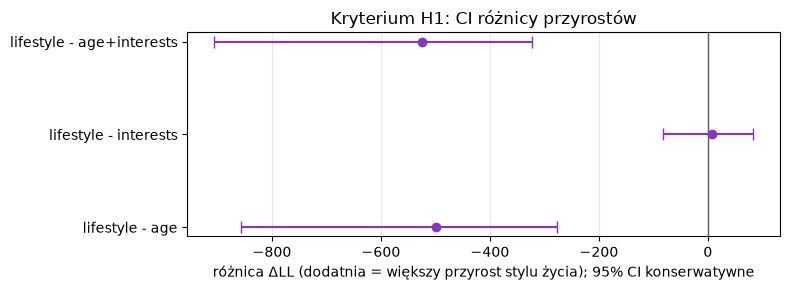

In [14]:
d_last = diff_ci[diff_ci["definition"] == "last"].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 3))
yy = np.arange(len(d_last))[::-1]
ax.errorbar(
    d_last["estimate"],
    yy,
    xerr=[
        d_last["estimate"] - d_last["ci_low_conservative"],
        d_last["ci_high_conservative"] - d_last["estimate"],
    ],
    fmt="o",
    color=PURPLE_INK,
    capsize=4,
)
ax.axvline(0, color=GRAY, lw=1)
ax.set_yticks(yy)
ax.set_yticklabels(d_last["contrast"])
ax.set_xlabel("różnica ΔLL (dodatnia = większy przyrost stylu życia); 95% CI konserwatywne")
ax.set_title("Kryterium H1: CI różnicy przyrostów")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 6.5 Test na przypadek: tasowanie stylu życia odbiorców (shuffled null baseline)

Losowo tasujemy cechy stylu życia między **odbiorcami** (całymi osobami, z zachowaniem liczby swipe'ów i popularności profilu) i porównujemy ΔLL stylu życia
(ponad kontrole, wiek i zainteresowania) z rozkładem z permutacji. Ten test już uwzględnia strukturę odbiorców, w odróżnieniu od ΔLL na poziomie swipe'ów.

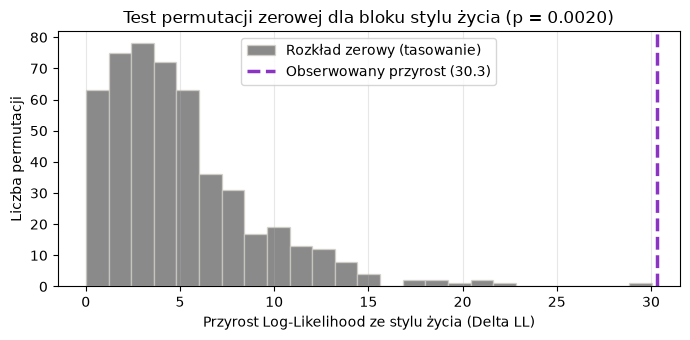

Obserwowany przyrost: 30.33; z tasowania: 5.07 (95%: [0.38, 14.73]); p = 0.0020 (min. rozdzielczość 0.0020)


In [15]:
obs_perm, null_lls, perm_p = cached(
    "perm_null", lambda: h1.permutation_null_lifestyle(df, n_perm=N_PERM, seed=SEED)
)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(
    null_lls, bins=25, color=GRAY, alpha=0.7, edgecolor=HAIR, label="Rozkład zerowy (tasowanie)"
)
ax.axvline(
    obs_perm,
    color=PURPLE_INK,
    lw=2.5,
    linestyle="--",
    label=f"Obserwowany przyrost ({obs_perm:.1f})",
)
ax.set_xlabel("Przyrost Log-Likelihood ze stylu życia (Delta LL)")
ax.set_ylabel("Liczba permutacji")
ax.set_title(f"Test permutacji zerowej dla bloku stylu życia (p = {perm_p:.4f})")
ax.legend(frameon=True)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
q025, q975 = np.quantile(null_lls, [0.025, 0.975])
print(
    f"Obserwowany przyrost: {obs_perm:.2f}; z tasowania: {null_lls.mean():.2f}"
    f" (95%: [{q025:.2f}, {q975:.2f}]); p = {perm_p:.4f}"
    f" (min. rozdzielczość {1 / (N_PERM + 1):.4f})"
)

## 7. Styl życia per pole (Z7, analiza drugorzędna i eksploracyjna)

Siedem pól strukturalnych (po uzupełnieniu tagami, D13). Dla każdego: status pary (zgodny / niezgodny / jedna strona brak / obie brak; poziomy rzadsze niż 50 swipe'ów łączone z „jedna strona brak”),
łączny test Walda (SE klastrowane dwustronnie), ΔLL pola jako ostatniego i pierwszego, **korekta Holma na 7 testów**.
Palenie osobno kierunkowo: `N` = niepalący, pozostałe kody = użytkownik (założenie bez codebooka). `cleanliness` i `noise_level` mogą być wartościami domyślnymi (P6) i mają prawie wspólne braki
(te same ok. 1% użytkowników), więc ich indywidualne współczynniki „brak danych” są niestabilne; interpretujemy tylko łączne testy.

In [16]:
field_res = cached("field_res", lambda: h1_audit.per_field_analysis(df))
print(f"n = {field_res['n']:,}")
display(field_res["fields"].round(4))
print("Palenie: kierunek (OR względem zgodnych kodów; SE klastrowane dwustronnie)")
display(field_res["smoking_direction"].round(3))
print(
    "Test symetrii (niepalący→użytkownik = użytkownik→niepalący):"
    f" p = {field_res['smoking_asymmetry_p']:.3f}"
)

n = 92,754


,field,df,dll_last,dll_first,wald_chi2,p_raw,possible_default,p_holm
0,daily_routine,3,2.7584,8.4213,2.6616,0.4468,False,1.0000
1,lifestyle,3,5.9115,24.5936,1.4987,0.6826,False,1.0000
2,work_from_home,3,54.6929,78.9194,4.0356,0.2576,False,1.0000
3,cleanliness,2,5.1752,32.5756,5.0379,0.0805,True,0.5638
4,noise_level,2,3.4868,30.0936,2.9854,0.2248,True,1.0000
5,smoking,3,53.1863,65.0602,4.5479,0.2081,False,1.0000
6,alcohol,3,25.9722,5.0883,1.8566,0.6027,False,1.0000


Palenie: kierunek (OR względem zgodnych kodów; SE klastrowane dwustronnie)


,level,or,ci_low,ci_high,p_value,n
0,both_missing,0.7320,0.5160,1.0380,0.0800,6826
1,nonsmoker_to_user,0.8610,0.7770,0.9530,0.0040,11798
2,one_missing,0.8330,0.6990,0.9920,0.0410,36712
3,user_to_nonsmoker,0.9340,0.6800,1.2840,0.6750,10319
4,user_vs_other_user,1.0390,0.7480,1.4430,0.8180,3155


Test symetrii (niepalący→użytkownik = użytkownik→niepalący): p = 0.657


## 8. Analizy wrażliwości (Z8)

12 scenariuszy; kolumna `status` mówi, czy scenariusz był zaplanowany przed audytem (D6, D7, G6, karta 3.2), czy dodany po nim.
`delta_ll_lifestyle` = ΔLL stylu życia jako ostatniego bloku; `delta_ll_interests` = ΔLL wieku+zainteresowań jako ostatniego bloku (nazwa historyczna);
`delta_ll_age_last` i `delta_ll_hobby_last` rozbijają go na pojedyncze bloki. W scenariuszu `spec_old` blok wieku zawiera `same_sex`.

,scenariusz,status,n_swipe,delta_ll_lifestyle,delta_r2_lifestyle,delta_ll_interests,delta_r2_interests,delta_ll_age_last,delta_ll_hobby_last
0,"main (as-of D7, brak Hyderabadu D10)",pre-rejestrowana,92754,30.3340,0.0010,554.4340,0.0120,529.4990,22.9940
1,tylko prior_version (D7),pre-rejestrowana,86653,22.1160,0.0010,524.4910,0.0120,500.4770,23.2260
2,oba prior_version (D7),pre-rejestrowana,46863,35.7430,0.0020,357.0700,0.0160,340.4640,15.4190
3,bez kont skrajnych (D6),pre-rejestrowana,76151,54.0650,0.0010,591.2720,0.0140,568.8030,20.4380
4,aktywni nadawcy >= 10 (D6),pre-rejestrowana,91102,29.5370,0.0010,548.1800,0.0120,525.7330,20.7280
5,"bez miasta ""inne"" (G6)",pre-rejestrowana,83358,34.0770,0.0010,425.0310,0.0100,398.9530,24.3670
6,"spec_old (same_sex w bloku wieku, bez kontroli...",post hoc (audyt),92754,32.1230,0.0010,748.3080,0.0160,723.8230,20.9770
7,same_sex zamiast sex_pair,post hoc (audyt),92754,27.1560,0.0010,900.7710,0.0190,875.5830,22.3430
8,+ |roznica pasm|^2 (karta 3.2),pre-rejestrowana,92754,30.2420,0.0010,566.8890,0.0120,541.9540,22.4460
9,+ efekty stale pasma nadawcy,post hoc (audyt),92754,29.3400,0.0010,381.0270,0.0080,356.7080,22.7260


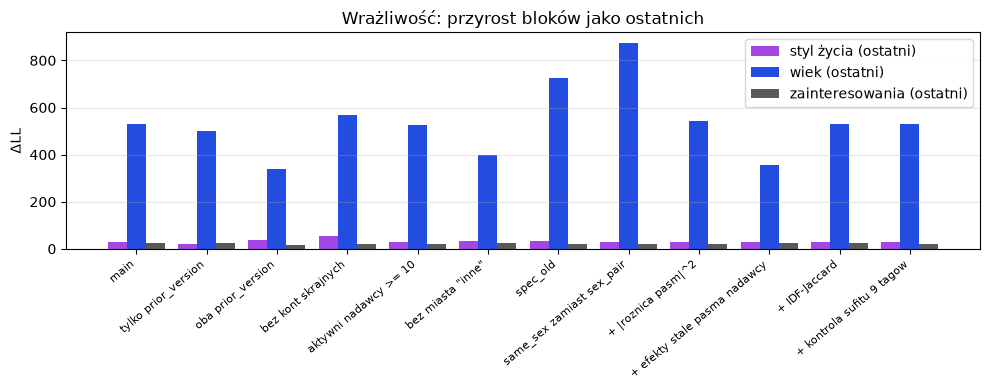

In [17]:
sens_df = cached("sens_df", lambda: h1.sensitivity_analysis_h1(df))
display(sens_df.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(sens_df))
w = 0.27
ax.bar(x - w, sens_df["delta_ll_lifestyle"], w, label="styl życia (ostatni)", color=PURPLE)
ax.bar(x, sens_df["delta_ll_age_last"], w, label="wiek (ostatni)", color=BLUE)
ax.bar(x + w, sens_df["delta_ll_hobby_last"], w, label="zainteresowania (ostatni)", color=GRAY)
ax.set_xticks(x)
ax.set_xticklabels(
    [s.split(" (")[0][:34] for s in sens_df["scenariusz"]], rotation=40, ha="right", fontsize=8
)
ax.set_ylabel("ΔLL")
ax.set_title("Wrażliwość: przyrost bloków jako ostatnich")
ax.legend(frameon=True)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 8b. Wrażliwość z CI (post hoc: walidacja tagów)

Dla każdego z 12 scenariuszy: ΔLL stylu życia (S) i wieku+zainteresowań (WZ) jako ostatniego bloku oraz ich różnica S − WZ, z konserwatywnym CI bootstrapu klastrowego (B = 1000, po nadawcach i odbiorcach; `scripts/h1_rebase_run.py`).
Pierwsza tabela: v1, druga: v0 dla porównania.

In [18]:
for ver in ("v1", "v0"):
    t12 = pd.read_csv(REBASE_DIR / f"sensitivity12_{ver}.csv")
    print(f"--- {ver} ---")
    display(t12.round(1))

--- v1 ---


,scenariusz,status,n_swipe,S,S_lo,S_hi,WZ,WZ_lo,WZ_hi,S-WZ,S-WZ_lo,S-WZ_hi,S-WZ_excludes0
0,"main (as-of D7, brak Hyderabadu D10)",pre-rejestrowana,92754,30.3000,7.6000,114.1000,554.4000,368.7000,953.7000,-524.1000,-905.6000,-323.4000,True
1,tylko prior_version (D7),pre-rejestrowana,86653,22.1000,3.9000,102.1000,524.5000,334.1000,895.4000,-502.4000,-839.9000,-298.1000,True
2,oba prior_version (D7),pre-rejestrowana,46863,35.7000,8.9000,122.2000,357.1000,180.1000,681.5000,-321.3000,-629.4000,-131.1000,True
3,bez kont skrajnych (D6),pre-rejestrowana,76151,54.1000,16.9000,149.6000,591.3000,387.6000,985.9000,-537.2000,-915.2000,-326.6000,True
4,aktywni nadawcy >= 10 (D6),pre-rejestrowana,91102,29.5000,5.5000,120.0000,548.2000,370.6000,962.8000,-518.6000,-896.6000,-325.6000,True
5,"bez miasta ""inne"" (G6)",pre-rejestrowana,83358,34.1000,5.9000,121.3000,425.0000,293.8000,779.0000,-391.0000,-713.0000,-237.5000,True
6,"spec_old (same_sex w bloku wieku, bez kontroli...",post hoc (audyt),92754,32.1000,6.8000,122.6000,748.3000,470.6000,1289.6000,-716.2000,-1231.3000,-419.7000,True
7,same_sex zamiast sex_pair,post hoc (audyt),92754,27.2000,5.8000,110.7000,900.8000,608.1000,1442.5000,-873.6000,-1411.2000,-558.8000,True
8,+ |roznica pasm|^2 (karta 3.2),pre-rejestrowana,92754,30.2000,7.6000,114.0000,566.9000,376.4000,1029.5000,-536.6000,-964.5000,-330.2000,True
9,+ efekty stale pasma nadawcy,post hoc (audyt),92754,29.3000,7.2000,110.6000,381.0000,274.0000,543.7000,-351.7000,-500.1000,-212.2000,True


--- v0 ---


,scenariusz,status,n_swipe,S,S_lo,S_hi,WZ,WZ_lo,WZ_hi,S-WZ,S-WZ_lo,S-WZ_hi,S-WZ_excludes0
0,"main (as-of D7, brak Hyderabadu D10)",pre-rejestrowana,92754,40.5000,10.4000,129.4000,545.0000,357.8000,940.1000,-504.5000,-883.4000,-300.8000,True
1,tylko prior_version (D7),pre-rejestrowana,86653,29.0000,6.3000,107.5000,515.5000,320.6000,878.4000,-486.6000,-815.0000,-278.8000,True
2,oba prior_version (D7),pre-rejestrowana,46863,37.3000,9.9000,118.3000,353.6000,175.2000,684.7000,-316.4000,-636.1000,-120.2000,True
3,bez kont skrajnych (D6),pre-rejestrowana,76151,66.1000,23.4000,162.8000,582.4000,376.1000,989.8000,-516.3000,-911.3000,-293.0000,True
4,aktywni nadawcy >= 10 (D6),pre-rejestrowana,91102,39.4000,9.0000,129.6000,539.0000,367.2000,959.4000,-499.6000,-887.3000,-302.6000,True
5,"bez miasta ""inne"" (G6)",pre-rejestrowana,83358,41.5000,10.8000,129.2000,414.1000,281.5000,786.4000,-372.6000,-696.3000,-210.7000,True
6,"spec_old (same_sex w bloku wieku, bez kontroli...",post hoc (audyt),92754,41.4000,9.5000,131.9000,739.1000,461.9000,1277.6000,-697.8000,-1219.3000,-395.7000,True
7,same_sex zamiast sex_pair,post hoc (audyt),92754,36.1000,8.3000,123.3000,889.9000,591.9000,1431.3000,-853.9000,-1389.2000,-550.7000,True
8,+ |roznica pasm|^2 (karta 3.2),pre-rejestrowana,92754,40.4000,10.2000,129.4000,557.6000,365.8000,1009.5000,-517.2000,-945.8000,-310.4000,True
9,+ efekty stale pasma nadawcy,post hoc (audyt),92754,38.5000,9.5000,122.3000,372.6000,262.2000,540.2000,-334.1000,-481.9000,-193.9000,True


## 9. Czy styl życia pomaga u nowych osób? Walidacja krzyżowa po nadawcach (D18, Z5)

5 foldów, każdy nadawca w jednym foldzie. Metryki: logloss, AUC, **AUC-PR** (dodane). Odchylenie między foldami opisuje zmienność uczenia, ale nie przedział różnicy modeli:
dlatego poniżej **sparowane różnice** liczone na predykcjach out-of-fold z bootstrapem po nadawcach (bootstrap jest warunkowy na dopasowanych modelach foldów, bez ponownego uczenia).
Dodatnie wartości = poprawa (dla logloss: spadek straty).

In [19]:
cv_res = cached("cv_res", lambda: h1.grouped_cv_h1(df, n_splits=N_FOLDS, seed=SEED))
keep = ["null", "controls", "age", "interests", "lifestyle", "age_interests", "full"]
cv_summary = cv_res.groupby("block")[["logloss", "auc", "auc_pr"]].agg(["mean", "std"]).loc[keep]
print("Średnie testowe z 5 foldów (± odchylenie między foldami)")
display(cv_summary.round(4))

Średnie testowe z 5 foldów (± odchylenie między foldami)


logloss           auc        auc_pr       
                 mean    std   mean    std   mean    std
block                                                   
null           0.5116 0.0320 0.5000 0.0000 0.2077 0.0238
controls       0.4946 0.0316 0.6160 0.0108 0.2781 0.0347
age            0.4892 0.0326 0.6424 0.0116 0.3091 0.0240
interests      0.4946 0.0315 0.6212 0.0079 0.2792 0.0258
lifestyle      0.4948 0.0319 0.6210 0.0042 0.2786 0.0227
age_interests  0.4892 0.0325 0.6431 0.0115 0.3090 0.0214
full           0.4895 0.0328 0.6430 0.0118 0.3054 0.0199

In [20]:
oof = cached("oof", lambda: h1_audit.oof_predictions(df, n_splits=N_FOLDS, seed=SEED))
cv_diff = cached(
    "cv_diff", lambda: h1_audit.paired_cv_differences(oof, n_boot=N_BOOT_CV, seed=SEED)
)
display(cv_diff[cv_diff["definition"] == "last"].round(5).reset_index(drop=True))
print("Definicja 'first' (przyrost ponad same kontrole):")
display(cv_diff[cv_diff["definition"] == "first"].round(5).reset_index(drop=True))

,metric,definition,contrast,estimate,ci_low,ci_high
0,logloss,last,gain: lifestyle,-0.0002,-0.0008,0.0004
1,logloss,last,gain: age+interests,0.0053,0.0022,0.0086
2,logloss,last,gain: interests,0.0000,-0.0006,0.0006
3,logloss,last,gain: age,0.0053,0.0021,0.0086
4,logloss,last,lifestyle - age+interests,-0.0055,-0.0087,-0.0024
5,logloss,last,lifestyle - interests,-0.0002,-0.0010,0.0005
6,logloss,last,lifestyle - age,-0.0055,-0.0089,-0.0022
7,auc,last,gain: lifestyle,0.0007,-0.0015,0.0030
8,auc,last,gain: age+interests,0.0252,0.0148,0.0349
9,auc,last,gain: interests,0.0002,-0.0021,0.0023


Definicja 'first' (przyrost ponad same kontrole):


,metric,definition,contrast,estimate,ci_low,ci_high
0,logloss,first,gain: lifestyle,-0.0002,-0.0009,0.0004
1,logloss,first,gain: age+interests,0.0053,0.0021,0.0085
2,logloss,first,gain: interests,-0.0000,-0.0006,0.0006
3,logloss,first,gain: age,0.0053,0.0022,0.0086
4,logloss,first,lifestyle - age+interests,-0.0055,-0.0087,-0.0024
5,logloss,first,lifestyle - interests,-0.0002,-0.0010,0.0006
6,logloss,first,lifestyle - age,-0.0056,-0.0090,-0.0023
7,auc,first,gain: lifestyle,0.0099,0.0036,0.0164
8,auc,first,gain: age+interests,0.0343,0.0220,0.0459
9,auc,first,gain: interests,0.0067,0.0005,0.0122


In [21]:
cv_lv = cached("cv_lv", lambda: h1_rebase.cv_levels(oof, n_boot=N_BOOT_CV, seed=SEED))
print("Poziomy zbiorcze out-of-fold (CI: bootstrap po nadawcach, warunkowy na modelach foldów):")
display(cv_lv.pivot(index="model", columns="metric", values="estimate").round(4))

Poziomy zbiorcze out-of-fold (CI: bootstrap po nadawcach, warunkowy na modelach foldów):


metric,auc,auc_pr,logloss
model,,,
age,0.6384,0.3018,0.4884
age_interests,0.6395,0.3011,0.4885
age_lifestyle,0.6400,0.2998,0.4887
controls,0.6051,0.2653,0.4937
full,0.6402,0.2988,0.4887
interests,0.6118,0.2691,0.4937
interests_lifestyle,0.6171,0.2709,0.4939
lifestyle,0.6150,0.2702,0.4940


## 9b. Wrażliwość na słownik tagów (Z4; post hoc: walidacja tagów)

Klasyfikacja tagów na hobby i styl życia pochodzi od **jednego recenzenta** (nie w pełni ślepego, bez testu powtórnego; `docs/tag-validation/decisions.md`). Sprawdzamy, jak H1 zależy od tej klasyfikacji:
v0 (mapowanie agenta), konsensus tylko A (mapowanie surowych tagów), tylko B (kategorie), A + B i v1 (A + B + scalenia). Dla każdego: ΔLL bloków (średnia po kolejnościach) z CI (bootstrap po nadawcach i odbiorcach, konserwatywny = szerszy),
różnice styl życia − zainteresowania / − wiek / − (wiek+zainteresowania), stosunek styl życia / zainteresowania oraz CV (ΔlogLoss stylu życia jako ostatniego bloku). Losowania są **te same** we wszystkich słownikach, więc różnice między słownikami liczymy parami.

In [22]:
dict_tbl = pd.read_csv(REBASE_DIR / "dictionary_sensitivity.csv")
keep = [
    c
    for c in dict_tbl.columns
    if "excludes0" not in c and not c.endswith("[last] lo") and not c.endswith("[last] hi")
]
display(dict_tbl[keep].set_index("label").T.round(3))

# blok v1 z notebooka = wiersz „vi” tabeli zbiorczej
mv = block_ci.set_index(["quantity", "definition"])
assert (
    abs(
        mv.loc[("ratio: lifestyle / interests", "mean"), "estimate"]
        - dict_tbl.set_index("scenario").loc["vi", "ratio: lifestyle / interests [mean]"]
    )
    < 1e-6
)

label,v0,konsensus A+B,konsensus A,konsensus B,v1
scenario,i,ii,iii,iv,vi
dll: age [mean],533.1895,533.4196,533.2087,533.4054,533.7716
dll: age [mean] lo,340.1880,341.6962,340.0743,341.6664,341.7788
dll: age [mean] hi,914.9878,915.4302,914.6672,915.7515,915.3874
dll: age [last],528.2500,528.7958,528.3217,528.7244,529.4986
dll: interests [mean],13.9264,23.6450,13.9723,23.5474,23.0897
dll: interests [mean] lo,2.3125,4.2686,2.3390,4.2195,4.0855
dll: interests [mean] hi,101.4238,118.4219,101.4605,118.1334,116.6786
dll: interests [last],13.4997,24.1055,13.6030,23.9469,22.9936
dll: lifestyle [mean],42.5085,40.3682,42.4475,40.5104,32.5852


**Zmiana względem v0 (parami, te same losowania).** `ci_low`/`ci_high` = konserwatywny (szerszy) z przedziałów po nadawcach i po odbiorcach.

In [23]:
chg = pd.read_csv(REBASE_DIR / "dictionary_change_vs_v0.csv")
want = [
    "dll: interests",
    "dll: lifestyle",
    "dll: age",
    "diff: lifestyle - interests",
    "ratio: lifestyle / interests",
]
display(
    chg[(chg["definition"] == "mean") & chg["quantity"].isin(want)].round(2).reset_index(drop=True)
)

,scenario,quantity,definition,estimate,ci_low_sender,ci_high_sender,ci_low_receiver,ci_high_receiver,ci_low,ci_high,wider_is,excludes_zero
0,ii,dll: age,mean,0.2300,-1.4000,2.5800,-1.0800,1.4500,-1.4000,2.5800,sender,False
1,ii,dll: interests,mean,9.7200,-24.2000,55.8200,1.4000,18.4400,-24.2000,55.8200,sender,False
2,ii,dll: lifestyle,mean,-2.1400,-16.0700,11.4000,-7.0800,2.4300,-16.0700,11.4000,sender,False
3,ii,diff: lifestyle - interests,mean,-11.8600,-65.2700,33.0500,-24.0800,-0.1500,-65.2700,33.0500,sender,False
4,ii,ratio: lifestyle / interests,mean,-1.3500,-17.0800,3.6100,-6.6700,-0.0600,-17.0800,3.6100,sender,False
5,iii,dll: age,mean,0.0200,-0.5500,0.5400,-0.2200,0.3200,-0.5500,0.5400,sender,False
6,iii,dll: interests,mean,0.0500,-0.2300,0.3900,-0.0400,0.1600,-0.2300,0.3900,sender,False
7,iii,dll: lifestyle,mean,-0.0600,-0.6300,0.6900,-0.7100,0.5700,-0.6300,0.6900,sender,False
8,iii,diff: lifestyle - interests,mean,-0.1100,-0.7000,0.7100,-0.7700,0.5200,-0.7000,0.7100,sender,False
9,iii,ratio: lifestyle / interests,mean,-0.0100,-0.2500,0.2000,-0.1100,0.0400,-0.2500,0.2000,sender,False


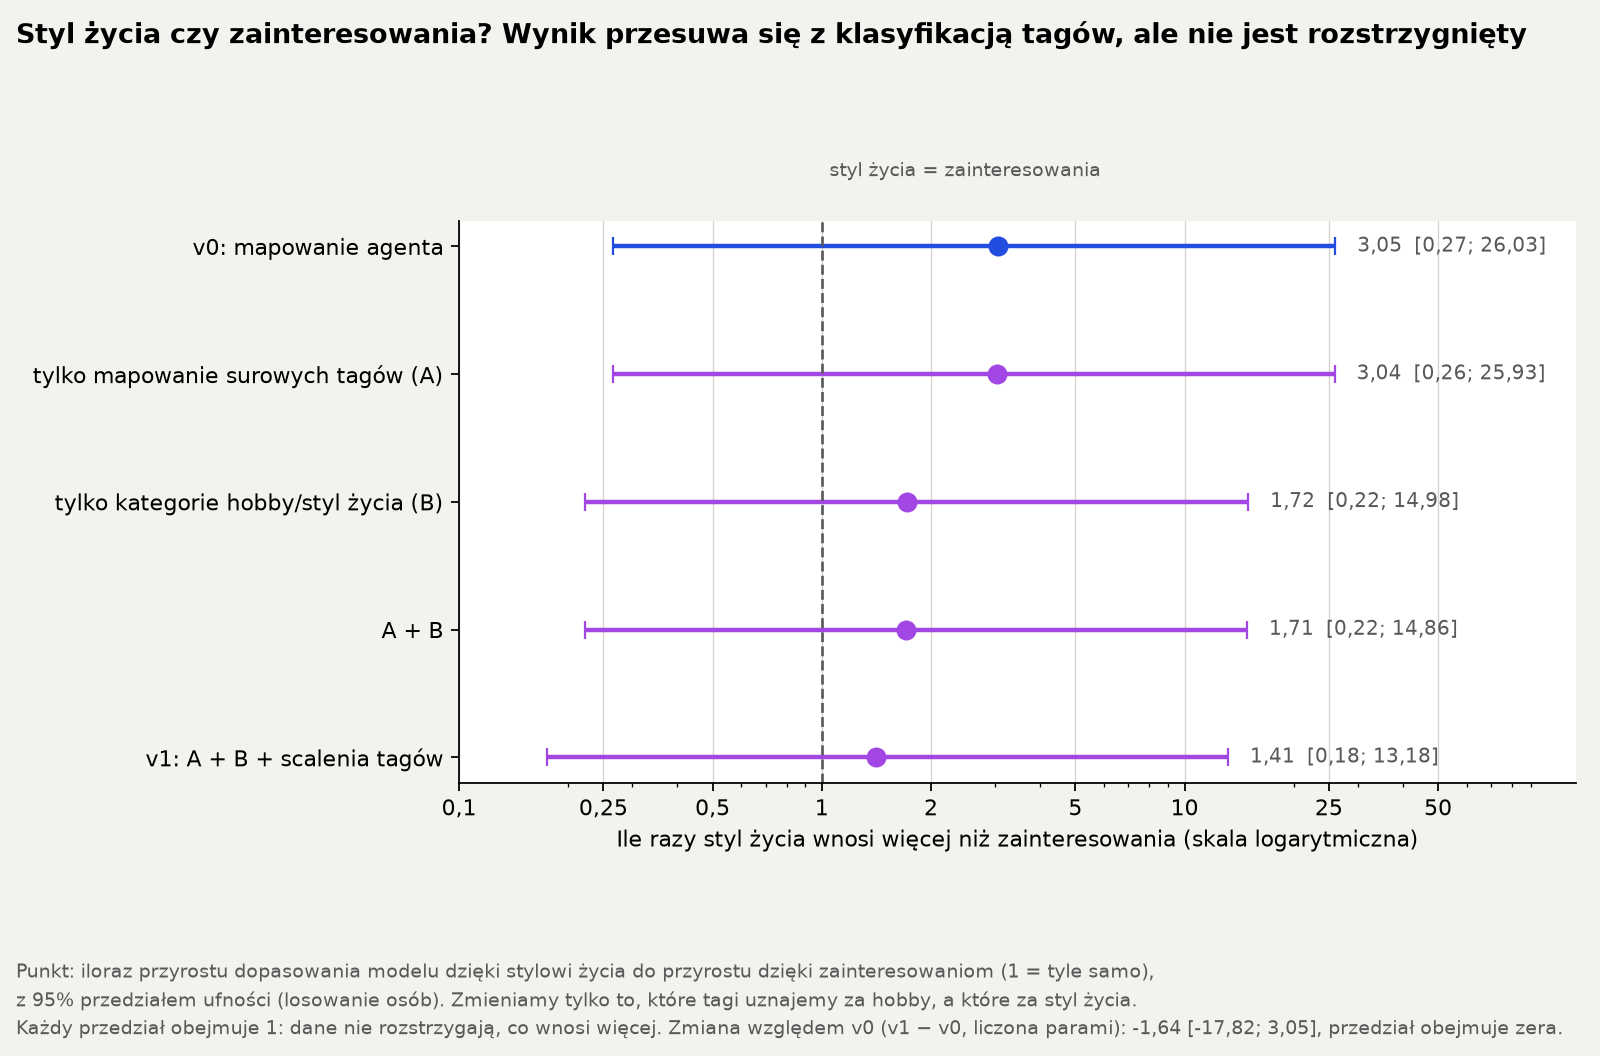

In [24]:
# Wykres z zapisanych liczb (reports/h1/rebase/*.csv): styl można zmieniać bez przeliczania.
# (Image zaimportowany w pierwszej komórce)

plot_tbl = pd.read_csv(REBASE_DIR / "dictionary_ratio_plot_data.csv")
note = (REBASE_DIR / "dictionary_ratio_plot_note.txt").read_text(encoding="utf-8").strip()
fig_path = h1_rebase.plot_dictionary_sensitivity(
    plot_tbl, REBASE_DIR / "dictionary_sensitivity.png", note=note
)
display(Image(filename=str(fig_path)))

**Dekompozycja: który tag odpowiada za zmianę.** Jeden refit (pooled logit, te same kontrole) na każdą pojedynczą decyzję przesuniętą względem v0 (kategoria jednego tagu, jedno scalenie, grupy nadpisań A, wszystkie zmiany B, wszystkie scalenia i całość = v1).
`delta_dll_*` = zmiana średniego ΔLL bloku względem v0 (ΔΔLL). Tylko liczby, bez interpretacji mechanizmu. Tagi `healthy_food`, `marketing_social`, `tech_it` mają w v0 i v1 tę samą kategorię (`unclear`), więc ich przesunięcie wynosi 0 z konstrukcji.

In [25]:
dec = pd.read_csv(REBASE_DIR / "decomposition.csv")
display(dec.drop(columns=["ratio_v0"]).round(3))

,shift,note,delta_dll_age,delta_dll_interests,delta_dll_lifestyle,share_interests_changed,share_lifestyle_tags_changed,share_conflict_changed,ratio
0,cooking,hobby → lifestyle,-0.2190,7.8110,-3.8150,0.4340,0.0610,0.0000,1.7800
1,instruments,hobby → lifestyle,0.1050,2.4900,-0.1170,0.0720,0.0010,0.0000,2.5820
2,vanlife,hobby → lifestyle,-0.0690,-0.2590,0.0650,0.0060,0.0000,0.0000,3.1150
3,long_talks,unclear → lifestyle,0.1910,-2.8700,1.6690,0.1620,0.0070,0.0000,3.9960
4,city_breaks,hobby → unclear,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,3.0520
5,healthy_food,unclear → unclear (bez różnicy względem v0),0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN
6,marketing_social,unclear → unclear (bez różnicy względem v0),0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN
7,tech_it,unclear → unclear (bez różnicy względem v0),0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN
8,quiet_evenings → likes_calm,scalenie,0.0840,-0.1840,-3.8620,0.0000,0.0150,0.0000,2.8120
9,peace_and_quite → likes_calm,scalenie,0.0160,0.0040,-0.0840,0.0000,0.0020,0.0010,3.0460


## 9c. Anomalia D15: skąd ~52% swipe'ów z konfliktem tagów (Z1)

Szczegóły: `docs/h1/d15-conflict-investigation.md`. Wniosek: **prawdziwa prewalencja, nie błąd** (odsetek konfliktów jest równy odsetkowi oczekiwanemu przy niezależności stron: permutacja tagów odbiorców). Kod zmiennej nie został zmieniony.
Poniżej: odsetek na próbie v1 liczony tu na żywo oraz rozkład po pięciu grupach polaryzacji z `reports/h1/d15_prevalence.json`.

In [26]:
d15 = json.loads(Path("../reports/h1/d15_prevalence.json").read_text(encoding="utf-8"))[
    "v1_candidate_vi"
]
live = h1.prepare_h1_sample(df)["lifestyle_tag_conflict"].mean()
assert abs(live - d15["conflict_rate_h1_sample"]) < 1e-12
base_any = d15["independence_baseline"]["any"]
print(
    f"Konflikt D15 na próbie H1 (v1): {live:.4f}; przy niezależności stron: "
    f"{base_any['perm_mean']:.4f} [{base_any['perm_lo']:.4f}; {base_any['perm_hi']:.4f}]"
)
grp = pd.DataFrame(d15["by_group"])
grp["niezależność"] = [d15["independence_baseline"][str(g)]["perm_mean"] for g in grp["group"]]
display(
    grp[
        [
            "group",
            "pos",
            "neg",
            "n_conflicts",
            "conflict_rate",
            "niezależność",
            "sender_any_tag",
            "receiver_any_tag",
        ]
    ].round(4)
)

Konflikt D15 na próbie H1 (v1): 0.5241; przy niezależności stron: 0.5251 [0.5227; 0.5273]


,group,pos,neg,n_conflicts,conflict_rate,niezależność,sender_any_tag,receiver_any_tag
0,0,smoker,non_smoker,15931,0.1718,0.1747,0.6375,0.6213
1,1,early_bird,night_owl,4062,0.0438,0.0450,0.3437,0.3539
2,2,extrovert,introvert,12844,0.1385,0.1387,0.5163,0.5279
3,3,no_pets,"animals,cat_person,dog_person",5945,0.0641,0.0631,0.4346,0.4436
4,4,"chill_at_home,likes_calm,mostly_home","likes_parties,music_nonstop",25674,0.2768,0.2772,0.6856,0.6711
5,any,,,48615,0.5241,0.5251,0.9654,0.9664


## 9d. Tabela v0 → v1: każda raportowana liczba z CI

Wszystko liczone od zera na v0 i v1 tym samym kodem i ziarnem 42 (`scripts/h1_rebase_run.py`); estymata [95% CI]. Bez CI: liczności, odsetki i p-wartości. `section` odsyła do tablicy dowodów.

In [27]:
rep = pd.read_csv(REBASE_DIR / "v0_v1_reported_numbers.csv")


def cell(est, lo, hi):
    if pd.isna(est):
        return ""
    return f"{est:.4g} [{lo:.4g}; {hi:.4g}]" if not pd.isna(lo) else f"{est:.4g}"


rep["v0"] = [
    cell(a, b, c)
    for a, b, c in zip(rep["estimate_v0"], rep["ci_low_v0"], rep["ci_high_v0"], strict=True)
]
rep["v1"] = [
    cell(a, b, c)
    for a, b, c in zip(rep["estimate_v1"], rep["ci_low_v1"], rep["ci_high_v1"], strict=True)
]
pd.set_option("display.max_rows", 400)
pd.set_option("display.max_colwidth", 80)
display(rep[["section", "quantity", "v0", "v1"]])

,section,quantity,v0,v1
0,CV poziomy,AUC (średnia z 5 foldów): age_interests,0.6423,0.6431
1,CV poziomy,AUC (średnia z 5 foldów): controls,0.616,0.616
2,CV poziomy,AUC (średnia z 5 foldów): full,0.6432,0.643
3,CV poziomy,"auc (OOF, zbiorczo): age",0.6384 [0.6082; 0.6689],0.6384 [0.6082; 0.6689]
4,CV poziomy,"auc (OOF, zbiorczo): age_interests",0.6386 [0.6093; 0.6689],0.6395 [0.6103; 0.6695]
5,CV poziomy,"auc (OOF, zbiorczo): controls",0.6051 [0.5763; 0.6349],0.6051 [0.5763; 0.6349]
6,CV poziomy,"auc (OOF, zbiorczo): full",0.6403 [0.6107; 0.6694],0.6402 [0.6109; 0.6689]
7,CV poziomy,"auc (OOF, zbiorczo): interests",0.6088 [0.5811; 0.6365],0.6118 [0.5849; 0.6384]
8,CV poziomy,"auc (OOF, zbiorczo): lifestyle",0.6163 [0.5887; 0.6438],0.615 [0.5877; 0.6423]
9,CV poziomy,"auc_pr (OOF, zbiorczo): age",0.3018 [0.2566; 0.3497],0.3018 [0.2566; 0.3497]


## 10. Walidacja instrumentu: normalizacja i klasyfikacja tagów (Z9)

Walidacja względem człowieka została wykonana jako **jeden recenzent, jedna runda** (`docs/tag-validation/decisions.md`; wynik rundy 1, nie w pełni ślepy, bez testu powtórnego): zadanie A (mapowanie surowy → kanoniczny, n = 128) zgodność 96,1%, κ 0,960 [0,928; 0,984]; zadanie B (kategorie, n = 68) zgodność agenta 86,8%, κ 0,756 [0,632; 0,868], zgodność ważona 92,3% przy regule ≥ 95% i κ ≥ 0,70, czyli reguła niespełniona, więc **kategorie pochodzą z decyzji końcowych** (v1). Te wartości pochodzą z pliku decyzji człowieka, nie z obliczeń w tym notebooku. Nie ma zgodności między wieloma recenzentami; κ dotyczy zgodności agenta z jednym recenzentem.
Wpływ decyzji na H1 jest w sekcji 9b (słownik) i w `reports/tag-validation/impact.md` (różnice punktowe, bez CI).

In [28]:
prop = pd.read_csv("../docs/tag_category_proposal.csv")
n_tags = len(prop)
n_agree = int((prop["proposed_category_claude"] == prop["proposed_category_gemini"]).sum())
print(
    f"Propozycje kategorii Claude vs Gemini: zgodne dla {n_agree} z {n_tags} tagów"
    f" ({n_agree / n_tags:.1%}); to NIE jest walidacja względem zbioru wzorcowego człowieka."
)

Propozycje kategorii Claude vs Gemini: zgodne dla 58 z 68 tagów (85.3%); to NIE jest walidacja względem zbioru wzorcowego człowieka.


## 11. Wniosek (po rebase na kontrakt v1)

Liczby w nawiasach odsyłają do **tablicy dowodów E1–E14** poniżej; każda liczba ma w notebooku odpowiednik (sekcje 6.4b, 9, 9b–9d) i w tabeli v0 → v1 (sekcja 9d). Badamy **prawy swipe w aplikacji**, nie faktyczny najem (D1, G9); wyniki opisują związki w obserwowanej ekspozycji (G1), bez interpretacji przyczynowej.
Dane: kontrakt v1 (końcowe decyzje walidacji tagów); wyniki na v0 (mapowanie agenta) podajemy obok. Wszystko poniżej o słowniku tagów jest `post hoc (walidacja tagów)`.

### Werdykt: H1 niepotwierdzona. Demografia wygrywa, deklarowane dopasowanie dodaje niewiele

Kryterium z karty wymaga, by przyrost po dodaniu stylu życia był **większy** niż po dodaniu wieku i zainteresowań, z CI różnicy bez zera. Jest odwrotnie: ΔΔLL (styl życia − wiek+zainteresowania) = −524,1 [−905,6; −323,4] na v1 (−504,5 [−883,4; −300,8] na v0; konserwatywne 95% CI, E3). Tak samo dla każdej definicji przyrostu (pierwszy / ostatni / średnia po kolejnościach) i **poza próbą**: w CV po nadawcach sparowane różnice przyrostów (styl życia − wiek+zainteresowania) są ujemne dla logloss (−0,0055 [−0,0087; −0,0024]), AUC (−0,0245 [−0,0353; −0,0133]) i AUC-PR (−0,0309 [−0,0485; −0,0172]; E4). We wszystkich 12 scenariuszach wrażliwości na v1: ΔLL stylu życia (ostatni) 22,1–54,1, ΔLL wieku+zainteresowań 357–901; różnica styl życia − wiek+zainteresowania jest ujemna i jej konserwatywne CI nie obejmuje zera w 12 z 12 scenariuszy (największa górna granica CI −131,1) (E11).

„Demografia” to tu wiek (blok wieku) wraz z kontrolami płci i miasta, „deklarowane dopasowanie” to styl życia i zainteresowania. Udział wieku w sumie ΔLL wynosi 90,6% [70,8; 96,0] na v1 (90,4% [73,2; 95,6] na v0) i 89,3–90,6% we wszystkich pięciu wariantach słownika (E12).

### Co niesie sygnał

1. **Wiek.** Średni ΔLL po 6 kolejnościach na v1: wiek 533,8 [341,8; 915,4], styl życia 32,6 [8,9; 118,4], zainteresowania 23,1 [4,1; 116,7] (v0: 533,2 [340,2; 915,0] / 42,5 [11,0; 135,9] / 13,9 [2,3; 101,4]; E2; przedziały to percentyle bootstrapu klastrowego przyrostów, szerokie i asymetryczne, patrz Q15). Różnica styl życia − wiek: −499,2 [−855,9; −276,8] (E3).
2. **Styl życia vs zainteresowania: nierozstrzygnięte i zależne od klasyfikacji tagów.** Stosunek ΔLL stylu życia do zainteresowań wynosi 3,05 [0,27; 26,03] na v0, 1,71 [0,22; 14,86] dla konsensusu A + B i 1,41 [0,18; 13,18] na v1 (E12): punktowo spada ze 3,05 do 1,4–1,7, ale przedziały obejmują 1 w każdym wariancie, a zmiana v1 − v0 ma przedział obejmujący zero po losowaniu nadawców (−1,64 (po nadawcach [−17,82; 3,05], po odbiorcach [−7,53; −0,27]); konserwatywnie bierzemy szerszy). Różnica ΔLL stylu życia − zainteresowania: 7,3 [−81,4; 83,0] na v1 (27,0 [−59,3; 106,4] na v0): znak dodatni, ale CI obejmuje zero w każdym wariancie słownika (E3, E12). W CV jedyny dotąd wynik na korzyść stylu życia nad zainteresowaniami, AUC jako blok *pierwszy*, wynosił na v0 0,0075 [0,0017; 0,0137], a na v1 0,0032 [−0,0033; 0,0093] (CI obejmuje zero), czyli **nie przetrwał zmiany klasyfikacji**. Nie traktujemy go jako wsparcia dla H1.
3. **Styl życia: słaby sygnał, bez mierzalnego zysku poza próbą.** Test tasowania odbiorców: ΔLL 30,3 wobec 5,1 [0,4; 14,7] z permutacji (p na poziomie minimum rozdzielczości 1/501). Jako ostatni blok nie poprawia CV: AUC 0,0007 [−0,0015; 0,0030], logloss −0,0002 [−0,0008; 0,0004], AUC-PR −0,0022 [−0,0063; 0,0012] (E5). Żadne z 7 pól nie przechodzi korekty Holma (najmniejsze p po Holmie 0,56, `cleanliness`; E8). Palenie: niepalący → użytkownik OR 0,86 [0,78; 0,95], asymetrii kierunkowej nie wykazano (p = 0,66; E9; eksploracyjnie).
4. **Wiek to kierunek, nie podobieństwo** (bez zmian względem v0; wiek nie zależy od słownika tagów): odbiorca młodszy o 1 pasmo OR 0,97 [0,87; 1,09], starszy o 1 0,62 [0,57; 0,68], starszy o 2 lub więcej 0,35 [0,29; 0,43] (E6); sama zgodność pasma OR 0,78 [0,56; 1,07].
5. **Zainteresowania.** Różnica średniego Jaccarda prawe − lewe: 0,0049 [−0,0008; 0,0108] na v1 (0,0040 [−0,0021; 0,0101] na v0); IDF-Jaccard 0,0042 [−0,0005; 0,0093]. CI po nadawcach obejmuje zero w obu wariantach (E7).

### Wrażliwość na słownik tagów

Klasyfikacja hobby/styl życia pochodzi od **jednego recenzenta** (nie w pełni ślepego, bez testu powtórnego; zadanie B: κ 0,756 [0,632; 0,868] względem agenta, reguła prereg niespełniona, więc użyto decyzji końcowych; `docs/tag-validation/decisions.md`). Granica hobby/styl życia wpływa na wynik porównania bloków:
- Dekompozycja (ΔΔLL względem v0, średni ΔLL bloku; E13): przesunięcie `cooking` do stylu życia zmienia ΔLL zainteresowań o 7,81 i stylu życia o −3,81; `instruments` 2,49 / −0,12; `long_talks` −2,87 / 1,67; `vanlife` −0,26 / 0,07; `city_breaks`, `healthy_food`, `marketing_social`, `tech_it` 0 (ta sama kategoria co w v0, w kodzie `unclear` trafia do zainteresowań jak hobby). Wszystkie scalenia razem: zainteresowania −0,41, styl życia −8,41; mapowanie surowych tagów (A) razem: 0,05 / −0,06.
- Zmiana v1 − v0 w średnim ΔLL (parami, CI po nadawcach i po odbiorcach): zainteresowania 9,2 (po nadawcach [−24,6; 54,4], po odbiorcach [1,0; 17,9]); styl życia −9,9 (po nadawcach [−34,0; 9,9], po odbiorcach [−17,9; −3,5]). Po losowaniu odbiorców zmiana jest wyraźna, po losowaniu nadawców nie; konserwatywnie (szerszy przedział) **nie rozstrzygamy**, czy zmiana jest istotna.
- **Wniosek o wieku jest od słownika niezależny**: udział wieku w ΔLL 89,3–90,6% w każdym wariancie, a kryterium H1 (CI różnicy przyrostów styl życia − wiek+zainteresowania) ma ten sam znak i wyklucza zero w każdym wariancie (E12).
- **Anomalia D15 (Z1):** odsetek swipe'ów z konfliktem tagów to 52,4% na v1 (52,3% na v0); jest to **prawdziwa prewalencja**, równa poziomowi oczekiwanemu przy niezależności stron (52,5%), więc kod zmiennej nie został zmieniony, a wpływu poprawki na blok stylu życia nie ma (E14). W kodzie są pięć grup polaryzacji; sama definicja konfliktu (np. grupa palenia dubluje pole `smoking`) czeka na decyzję zespołu (Q13).
- Scenariusze diagnostyczne z zastępczym kodem pola `lifestyle` uzupełnianym z `often_out` (Z5 walidacji tagów) to **założenie, nie dane**; nie są podstawą żadnego wniosku.

### Zastrzeżenia

- **Rozdzielczość pomiaru.** Pola stylu życia mają 74–81% braków na poziomie profili (G14; dotyczy 5 z 7 pól). Na poziomie par odsetek swipe'ów z brakiem u którejkolwiek strony to 47–92% dla tych pól (E10), a `cleanliness` i `noise_level` (ok. 2%) mogą być wartościami domyślnymi (P6). Wiek jest kompletny, ale gruby (4 pasma). Słaby przyrost stylu życia nie dowodzi, że styl życia nie ma znaczenia, a jedynie że **ten pomiar** niewiele dodaje.
- **Widoczność cech (hipoteza niezweryfikowana).** Możliwe, że wiek jest dla użytkowników bardziej widoczny niż pola stylu życia; dane tego nie rozstrzygają (brak zdjęć, G5; widoczność pól i tagów to pytanie do dostawcy, karta 2.2).
- **Słownik tagów: jeden recenzent**, nie w pełni ślepy, bez testu powtórnego; porównanie stylu życia z zainteresowaniami zależy od granicy hobby/styl życia (patrz wyżej).
- **Próba i ekspozycja.** 92 754 swipe'ów (1525 nadawców, 1354 odbiorców; E1); feed może zawężać wariancję zmiennych (G1); 65% wyświetlanych profili to pasmo 18-20 (G13); wąska, studencka próba (G6).
- **Specyfikacja zmieniona po obejrzeniu wyników** (audyt: kontrole, wiek) i **analizy słownika po obejrzeniu wyników walidacji tagów**: stopnie swobody badacza; raportujemy wszystkie warianty.
- **Techniczne:** ΔLL na poziomie swipe'a zakłada niezależność i zawyża dowód; CI przyrostów ΔLL to percentyle bootstrapu bez korekty obciążenia (Q15); CI w CV są warunkowe na dopasowanych modelach foldów; brak modelu z efektami losowymi; 963 swipe'y bez żadnego wspólnie znanego pola stylu życia wypadają z modelu.

### Co jest konfirmacyjne, a co eksploracyjne

| Analiza | Status | Uwaga |
|---|---|---|
| Kryterium H1: CI różnicy przyrostów ΔLL, obie kolejności, bootstrap po nadawcach i odbiorcach | **konfirmacyjna** (karta 4, H1; D16) | specyfikacja kontroli poprawiona po audycie (post hoc); przeliczone na v1 |
| CV po użytkownikach: logloss, AUC, AUC-PR, sparowane różnice | **konfirmacyjna** (karta 3.3; D18) | CI warunkowe na dopasowanych modelach foldów; B = 1000 |
| Test tasowania stylu życia odbiorców | konfirmacyjna (null baseline z zasad kursu) | |
| Scenariusze D6, D7, G6; `\|Δ\|²`; IDF-Jaccard; baseline losowych par | pre-rejestrowana wrażliwość (A6, karta 3.2, 4) | |
| `sex_pair` zamiast `same_sex`; `spec_old`; efekty stałe pasma nadawcy; kontrola sufitu 9 tagów | **post hoc (audyt)** | wszystkie raportowane |
| Rozkład na 3 bloki (Shapley), ΔLL/df, ΔAIC; kierunek wieku | **eksploracyjna / post hoc (audyt)** | |
| Analiza per pole, kierunek palenia, Holm | **eksploracyjna** (drugorzędna, D16) | Holm tylko na 7 testów pól |
| Kontrakt v1 (decyzje walidacji tagów); wrażliwość na słownik z CI; stosunek styl życia / zainteresowania; dekompozycja tagów; 12 scenariuszy z CI; CI dla przyrostów bloków | **post hoc (walidacja tagów)** | wszystko z Z3–Z4 tego rebase; nie jest potwierdzeniem H1 |
| Anomalia D15 (prewalencja konfliktu) | **post hoc (walidacja tagów)** | diagnostyka, bez zmiany zmiennej |

### Tablica dowodów

In [29]:
# Tablica dowodów: każdy wniosek z sekcji 11 ma tu odpowiadającą mu liczbę z przedziałem lub p.
def ci(lo, hi, nd=2):
    return f"[{lo:.{nd}f}; {hi:.{nd}f}]"


def get(tbl, **kw):
    m = np.ones(len(tbl), bool)
    for k, v in kw.items():
        m &= (tbl[k] == v).to_numpy()
    return tbl[m].iloc[0]


inc_i = inc.set_index("block")


def r_last(c):
    return get(diff_ci, definition="last", contrast=c)


def cvl(metric, c, d="last"):
    return get(cv_diff, metric=metric, definition=d, contrast=c)


pooled = age_res["pooled"].set_index("term")
fields = field_res["fields"].set_index("field")
smk = field_res["smoking_direction"].set_index("level")
ps = perm_plain["summary"].set_index("group")
sens_idx = sens_df.set_index("scenariusz")

rows = []


def add(eid, claim, value, interval, note=""):
    rows.append(
        {"id": eid, "twierdzenie": claim, "liczba": value, "CI / p": interval, "uwaga": note}
    )


add(
    "E1",
    "Próba główna H1",
    f"{h1_res['data_len']:,} swipe'ów",
    "",
    f"{int(funnel.iloc[-1]['senders'])} nadawców, {int(funnel.iloc[-1]['receivers'])} odbiorców",
)
for b, lab in [("age", "wiek"), ("interests", "zainteresowania"), ("lifestyle", "styl życia")]:
    add(
        "E2",
        f"Średni ΔLL bloku: {lab}",
        f"{inc_i.loc[b, 'dll_mean']:.1f}",
        "",
        f"dLL/df {inc_i.loc[b, 'dll_mean_per_df']:.1f}; naiwne (bez klastrowania)",
    )
for c in ["lifestyle - age+interests", "lifestyle - age", "lifestyle - interests"]:
    r = r_last(c)
    add(
        "E3",
        f"ΔΔLL (ostatni): {c}",
        f"{r['estimate']:.1f}",
        ci(r["ci_low_conservative"], r["ci_high_conservative"], 1),
        f"szerszy: {r['wider_is']}; wyklucza 0: {bool(r['excludes_zero_conservative'])}",
    )
for metric in ["logloss", "auc", "auc_pr"]:
    r = cvl(metric, "lifestyle - age+interests")
    add(
        "E4",
        f"CV, różnica przyrostów (ostatni), {metric}: styl życia − wiek+zainteresowania",
        f"{r['estimate']:.4f}",
        ci(r["ci_low"], r["ci_high"], 4),
        "dodatnia = styl życia lepszy",
    )
for metric in ["logloss", "auc", "auc_pr"]:
    r = cvl(metric, "gain: lifestyle")
    add(
        "E5",
        f"CV, przyrost stylu życia jako ostatniego bloku, {metric}",
        f"{r['estimate']:.4f}",
        ci(r["ci_low"], r["ci_high"], 4),
        "dodatnia = poprawa",
    )
for t in ["younger_by_1", "older_by_1", "older_by_2plus"]:
    add(
        "E6",
        f"Wiek, OR względem tego samego pasma: {t}",
        f"{pooled.loc[t, 'or']:.2f}",
        ci(pooled.loc[t, "ci_low"], pooled.loc[t, "ci_high"]),
        "FE pasma nadawcy; SE po nadawcy",
    )
r = ps.loc["right_minus_left"]
add(
    "E7",
    "Hobby: Jaccard prawych − lewych (obserwowane)",
    f"{r['observed']:.4f}",
    ci(r["obs_ci_low"], r["obs_ci_high"], 4),
    f"baseline permutacji: {r['perm_mean']:.4f} {ci(r['perm_lo'], r['perm_hi'], 4)};"
    f" CI klastrowane obejmuje 0: {bool(r['obs_ci_low'] <= 0 <= r['obs_ci_high'])}",
)
r = perm_idf["summary"].set_index("group").loc["right_minus_left"]
add(
    "E7",
    "Hobby (IDF-Jaccard): prawe − lewe",
    f"{r['observed']:.4f}",
    ci(r["obs_ci_low"], r["obs_ci_high"], 4),
    f"baseline: {r['perm_mean']:.4f}",
)
add(
    "E8",
    "Styl życia per pole: najmniejsze p po Holmie",
    f"{fields['p_holm'].min():.3f}",
    "",
    f"pole: {fields['p_holm'].idxmin()};"
    f" liczba pól z p_holm < 0.05: {(fields['p_holm'] < 0.05).sum()} z 7",
)
r = smk.loc["nonsmoker_to_user"]
add(
    "E9",
    "Palenie: niepalący → użytkownik, OR",
    f"{r['or']:.2f}",
    ci(r["ci_low"], r["ci_high"]),
    f"test symetrii p = {field_res['smoking_asymmetry_p']:.2f}",
)
miss = {
    f: float((df[f"lsf_{f}"].isin(["one_missing", "both_missing"])).mean())
    for f in [
        "daily_routine",
        "lifestyle",
        "work_from_home",
        "smoking",
        "alcohol",
        "cleanliness",
        "noise_level",
    ]
}
add(
    "E10",
    "Rozdzielczość pomiaru: udział swipe'ów z brakiem pola u którejkolwiek strony"
    " (min–max po polach)",
    f"{min(miss.values()):.0%}–{max(miss.values()):.0%}",
    "",
    "; ".join(f"{k} {v:.0%}" for k, v in miss.items()),
)
sc = sens_idx["delta_ll_lifestyle"]
add(
    "E11",
    "Wrażliwość: zakres ΔLL stylu życia (ostatni) po 12 scenariuszach",
    f"{sc.min():.1f}–{sc.max():.1f}",
    "",
    "zakres ΔLL wieku+zainteresowań:"
    f" {sens_idx['delta_ll_interests'].min():.0f}–{sens_idx['delta_ll_interests'].max():.0f}",
)

pd.set_option("display.max_colwidth", 140)

# --- dodatek v1 (post hoc: walidacja tagów): liczby z reports/h1/rebase (jak w 9b-9d)
dict_tbl = pd.read_csv(REBASE_DIR / "dictionary_sensitivity.csv").set_index("scenario")
rq = "ratio: lifestyle / interests [mean]"
for k, lab in [("i", "v0"), ("ii", "A+B"), ("vi", "v1")]:
    r = dict_tbl.loc[k]
    add(
        "E12",
        f"Stosunek ΔLL styl życia / zainteresowania, słownik {lab}",
        f"{r[rq]:.2f}",
        ci(r[rq + " lo"], r[rq + " hi"], 2),
        f"udział wieku w ΔLL {r['share: age [mean]']:.1%}",
    )
for k, lab in [("i", "v0"), ("vi", "v1")]:
    r = dict_tbl.loc[k]
    add(
        "E12",
        f"ΔΔLL styl życia − zainteresowania (ostatni), {lab}",
        f"{r['diff: lifestyle - interests [last]']:.1f}",
        ci(
            r["diff: lifestyle - interests [last] lo"],
            r["diff: lifestyle - interests [last] hi"],
            1,
        ),
        "znak dodatni, CI obejmuje 0",
    )
chg_t = pd.read_csv(REBASE_DIR / "dictionary_change_vs_v0.csv")
r = chg_t[
    (chg_t["scenario"] == "vi")
    & (chg_t["definition"] == "mean")
    & (chg_t["quantity"] == "dll: interests")
].iloc[0]
add(
    "E13",
    "Zmiana ΔLL zainteresowań v1 − v0 (parami)",
    f"{r['estimate']:.1f}",
    ci(r["ci_low"], r["ci_high"], 1),
    f"po nadawcach {ci(r['ci_low_sender'], r['ci_high_sender'], 1)}; po odbiorcach {ci(r['ci_low_receiver'], r['ci_high_receiver'], 1)}",  # noqa: E501
)
dec_t = pd.read_csv(REBASE_DIR / "decomposition.csv").set_index("shift")
add(
    "E13",
    "Dekompozycja: `cooking` hobby → styl życia, ΔΔLL zainteresowań / stylu życia",
    f"{dec_t.loc['cooking', 'delta_dll_interests']:.2f} / {dec_t.loc['cooking', 'delta_dll_lifestyle']:.2f}",  # noqa: E501
    "",
    "jeden refit, bez CI (punktowo)",
)
d15_t = json.loads(Path("../reports/h1/d15_prevalence.json").read_text(encoding="utf-8"))[
    "v1_candidate_vi"
]
b = d15_t["independence_baseline"]["any"]
add(
    "E14",
    "Konflikt D15: odsetek swipe'ów (próba H1, v1) vs przy niezależności stron",
    f"{d15_t['conflict_rate_h1_sample']:.4f}",
    f"{b['perm_mean']:.4f} {ci(b['perm_lo'], b['perm_hi'], 4)}",
    "prawdziwa prewalencja, nie błąd",
)
evidence = pd.DataFrame(rows)
display(evidence)

,id,twierdzenie,liczba,CI / p,uwaga
0,E1,Próba główna H1,"92,754 swipe'ów",,"1525 nadawców, 1354 odbiorców"
1,E2,Średni ΔLL bloku: wiek,533.8,,dLL/df 177.9; naiwne (bez klastrowania)
2,E2,Średni ΔLL bloku: zainteresowania,23.1,,dLL/df 7.7; naiwne (bez klastrowania)
3,E2,Średni ΔLL bloku: styl życia,32.6,,dLL/df 10.9; naiwne (bez klastrowania)
4,E3,ΔΔLL (ostatni): lifestyle - age+interests,-524.1,[-905.6; -323.4],szerszy: sender; wyklucza 0: True
5,E3,ΔΔLL (ostatni): lifestyle - age,-499.2,[-855.9; -276.8],szerszy: sender; wyklucza 0: True
6,E3,ΔΔLL (ostatni): lifestyle - interests,7.3,[-81.4; 83.0],szerszy: sender; wyklucza 0: False
7,E4,"CV, różnica przyrostów (ostatni), logloss: styl życia − wiek+zainteresowania",-0.0055,[-0.0087; -0.0024],dodatnia = styl życia lepszy
8,E4,"CV, różnica przyrostów (ostatni), auc: styl życia − wiek+zainteresowania",-0.0245,[-0.0353; -0.0133],dodatnia = styl życia lepszy
9,E4,"CV, różnica przyrostów (ostatni), auc_pr: styl życia − wiek+zainteresowania",-0.0309,[-0.0485; -0.0172],dodatnia = styl życia lepszy
